# Modelling Phase and Results
## Notebook 4
### Introduction

In this notebook I implement and evaluate various machine learning models that predict the Credit Score of a customer.
Furthermore, I conclude by summarising the results and demonstrating various next-steps and recommendations for future development.

Each model applies a different approach to learning patterns within data, and offers distinct strengths and weaknesses. The models evaluated in this notebook are **Logistic Regression, Decision Trees, K-Nearest Neighbor (KNN), Support Vector Machines (SVM) Classifiers, Random Forests, and Gradient Boosting Classifiers**. More specifically:

- **Logistic Regression** is a simple yet powerful linear model that is widely used for classification problems, particularly when the dataset in question is binary.
- **Decision Trees** are non-parametric models that split the data based on specific conditions, forming a tree structure. It's a straightforward and easily interpretable model.
- **K-Nearest Neighbors** (KNN) is a lazy learning algorithm that classifies instances based on their similarity to instances in the training data.
- **Support Vector Machines** (SVM) are a set of supervised learning methods used for classification and regression. SVMs can handle both linear and non-linear data.
- Both **Random Forests** and **Gradient Boosting Classifiers** are ensemble methods. While Random Forests create a set of uncorrelated trees and combine them for prediction, Gradient Boosting Classifiers build weak learners (decision trees) in a sequential manner trying to correct the mistakes of the previous trees.

In order to maximize each model's performance, we will use **GridSearchCV** for **hyperparameter tuning**. This method exhaustively searches through a specified parameter grid, cross-validates each combination, and returns the parameters with the highest score based on a specified metric (AUC-ROC score).

Following the implementation and optimisation stage, we will **evaluate and compare the performance of our trained models**. This evaluation on the test dataset, will be based on various metrics including **AUC (Area Under the Curve)** which is a comprehensive measure for multiclass classification and **ROC (Receiver Operating Characteristic) curves** which show the trade-off between the true positive rate and false positive rate.

### Imports and function initialisations

In [1]:
# to show images from folders:
from IPython.display import Image

# to hide all warnings:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV

# sklearn preprocessors and pipelines:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, LabelBinarizer
from sklearn.compose import  make_column_transformer
from sklearn.pipeline import Pipeline


# sklearn models:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

#sklearn metrics
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score, classification_report, roc_curve, auc, confusion_matrix

# yellowbrick's visualisations
from yellowbrick.classifier import PrecisionRecallCurve, ClassPredictionError

#needed in case
import importlib
from custom_functions import preprocessor, model_results_plots
importlib.reload(preprocessor)
importlib.reload(model_results_plots)

# from custom_functions directory inside preprocessor.py you can reference Preprocessor_function:
from custom_functions.preprocessor import Preprocessor_function


Below I import the custom functions:
- **multiclass_roc_auc_score_and_plot**
- **class_prediction_error_plot**
- **precision_recall_curve_plot**
- **all_models_metrics**
- **plot_confusion_matrix**

To easily plot various metrics including ROC Curves and AUC scores.

In [2]:
# from custom_functions directory inside model_results_plots.py you can reference:
# -> multiclass_roc_auc_score_and_plot
# -> class_prediction_error_plot
# -> precision_recall_curve_plot

from custom_functions.model_results_plots \
    import multiclass_roc_auc_score_and_plot, class_prediction_error_plot, precision_recall_curve_plot, all_models_metrics, plot_confusion_matrix

### Importing and splitting the dataset
Below I import the data and follow the splitting strategy that was mentioned in Notebook 3.
I am importing the small subset (12500 observations, 11 features).

In [3]:
data = pd.read_csv('data_clean/for_models_dataset.csv')

X = data.drop(columns=['Customer_ID', 'Credit_Score'])
y = data['Credit_Score']

X_train, X_test, y_train, y_test = \
    train_test_split(X, y,
                     random_state=42,
                     test_size=0.2,
                     stratify=y)

target_names = ['Good', 'Poor', 'Standard'] # needed for classification report

### Baseline Accuracy to be achieved by classifiers:
The concept of **Baseline Accuracy** forms a crucial part of an analytical project as it signifies the simplest model's performance, typically used as a comparison measure. In machine learning, determining this Baseline Accuracy helps us to comprehend whether our model is genuinely useful and whether it has genuine predictive power. If a model's accuracy is below this threshold we should not use the created model for predictions.

A way to calculate Baseline Accuracy is to use value_counts and max(). In other words, I calculate the relative frequencies of the unique values and then choose the maximum. 

In [4]:
print(f"Baseline accuracy: {y_test.value_counts(normalize=True).max()*100:.2f}%\n\n")

baseline_accuracy = y_test.value_counts(normalize=True)
print(f"Baseline accuracy (class: Standard): {baseline_accuracy.iloc[0]*100:.2f}%")
print(f"Baseline accuracy (class: Poor): {baseline_accuracy.iloc[1]*100:.2f}%")
print(f"Baseline accuracy (class: Good): {baseline_accuracy.iloc[2]*100:.2f}%")

Baseline accuracy: 51.88%


Baseline accuracy (class: Standard): 51.88%
Baseline accuracy (class: Poor): 28.80%
Baseline accuracy (class: Good): 19.32%


As mentioned above, I remind that the baseline accuracy should be the minimum accuracy achieved by the created classifier. In my case, I should achieve an accuracy equal or greater than **51.88%**.

#### Creating column transformers with the Preprocessor_function
Refer to **notebook 2** to understand why I include the features:
- **Credit_Utilization_Ratio**
- **Occupation**
- **Payment_Behaviour**
into the **excluded_features** list. 

Below I create 2 preprocessors as described in **Notebook 3**. These preprocessors will be part of the models' pipelines. The preprocessor that uses **One-Hot Encoding** will be used on Pipelines that will contain Logistic Regression, KNN and SVM classifiers. On the other hand, **Ordinal Encoding** will be used on Pipelines that contain tree-based estimators and ensemble learning methods.

In [5]:
excluded_features = ['Customer_ID', 'Credit_Utilization_Ratio', 'Occupation', 'Payment_Behaviour']
pr_oh = \
    Preprocessor_function(data = data,
                          target_variable = 'Credit_Score',
                          cat_encoder = 'oh',
                          excluded_features = excluded_features
                          ).fit(data)


pr_ord = \
    Preprocessor_function(data = data,
                          target_variable = 'Credit_Score',
                          cat_encoder = 'ord',
                          excluded_features = excluded_features
                          ).fit(data)

pr_oh

ColumnTransformer(transformers=[('standardscaler', StandardScaler(),
                                 ['Age', 'Annual_Income', 'Outstanding_Debt',
                                  'Total_EMI_per_month', 'Delay_from_due_date',
                                  'Num_of_Delayed_Payment']),
                                ('onehotencoder',
                                 OneHotEncoder(drop='if_binary'),
                                 ['Credit_Mix', 'Payment_of_Min_Amount'])])

## Modelling Phase

In modelling phase, I will create Pipelines using the above-mentioned preprocessors and various estimators/ classifiers. I will fit/train the models on the training data and evaluate them on test data (in case of hyperparameters' optimisation I will use GridSearchCV algorithm).

**More specifically, every model will be evaluated (on the test data) by**:

- Creating a **classification report** with various metrics including, accuracy, f1-score, recall, precision per target classes.
- Plotting a visualisation of **Receiver Operating Characteristic (ROC)** that also contains the **AUC scores**.
- Plotting the **class prediction error** of the trained model as a bar plot. Each bar will be segmented to show the proportion of predictions (including false negatives and false positives, like a Confusion Matrix) for each class.
- Plotting the **Precision-Recall curve** of the trained model. A precision-recall curve is a metric used to evaluate a classifier's quality, especially when classes are imbalanced. It shows the tradeoff between precision, a measure of result relevancy, and recall, a measure of completeness. Precision is the ratio of true positives to the sum of true and false positives, while recall is the ratio of true positives to the sum of true positives and false negatives. A high area under the curve represents both high recall and high precision, indicating a model that returns accurate results for the majority of classes it selects.


**In addition, I choose to optimise and evaluate my models mainly based on AUC scores for the reasons below**:
- AUC score helps us understand how well the model is able to distinguish between classes at different cutoff levels.
- The AUC gives higher value to correctly classified instances. The **higher the AUC**, the **better the model's performance** in distinguishing between classes.
- The AUC is a useful metric for **imbalanced classes**.
- AUC delivers a performance metric which is effectively a rank-based measure of performance, and as such, it isn't sensitive to the scale of predicted probabilities. Whether my classifier delivers probabilities between 0.1 and 0.5, or 0.9 and 1, won't in itself affect the AUC.

### Initial Models
Below I create a pipeline with a **simple Logistic Regression Classifier**:

In [6]:
# creation of the estimator pipeline:
model_lr = \
Pipeline([
    ('preprocessor',pr_oh),
    ('estimator', LogisticRegression(multi_class='multinomial', random_state=42))
])

# training of the estimator pipeline:
model_lr.fit(X_train, y_train)

# printing the classification report:
print(classification_report(y_test, model_lr.predict(X_test),
                            target_names=target_names))

# plotting the ROC curves and exporting the AUC scores on auc_scores_simple_lr variable:
auc_scores_simple_lr = multiclass_roc_auc_score_and_plot(model_lr, X_test, y_test, model_name='Simple Logistic Regression')

# plotting the class prediction errors:
class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = model_lr,
                            is_fitted = True);


# plotting the precision recall curve:
precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = model_lr,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

              precision    recall  f1-score   support

        Good       0.50      0.51      0.51       483
        Poor       0.54      0.35      0.42       720
    Standard       0.59      0.70      0.64      1297

    accuracy                           0.56      2500
   macro avg       0.54      0.52      0.52      2500
weighted avg       0.56      0.56      0.55      2500



<Figure size 800x550 with 1 Axes>

<Figure size 800x550 with 1 Axes>

<Figure size 800x550 with 1 Axes>

**Important note**: All the models below will be demonstrated and evaluated in a similar logic as the model above.

Below I create a pipeline with a **simple KNN Classifier**:

              precision    recall  f1-score   support

        Good       0.50      0.51      0.50       483
        Poor       0.57      0.53      0.55       720
    Standard       0.63      0.66      0.65      1297

    accuracy                           0.59      2500
   macro avg       0.57      0.56      0.57      2500
weighted avg       0.59      0.59      0.59      2500



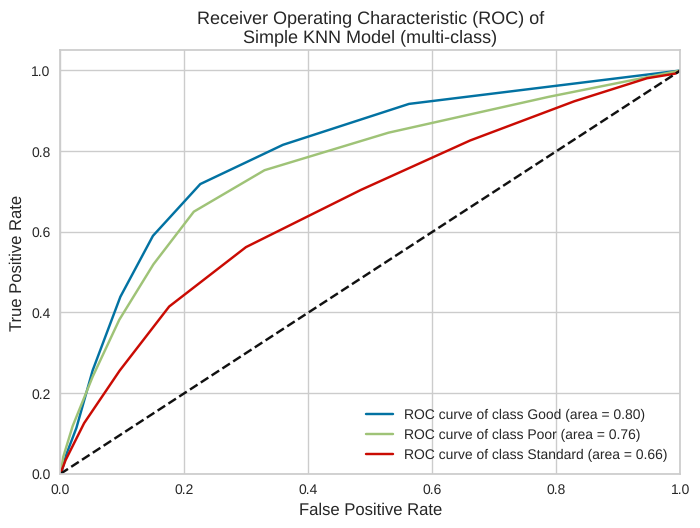

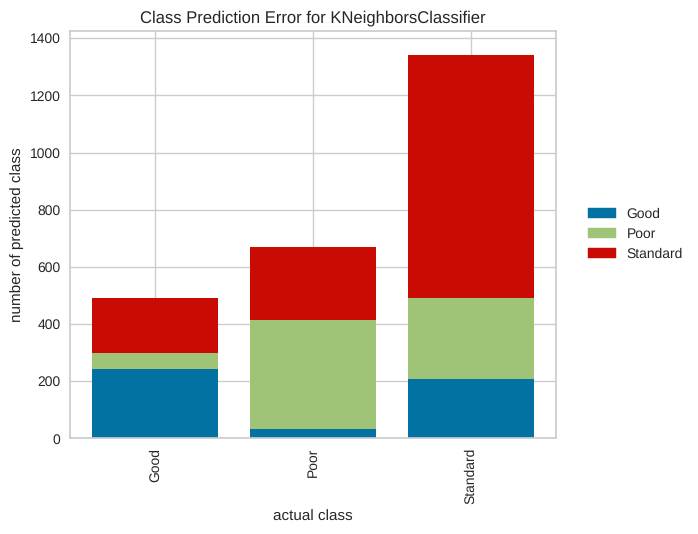

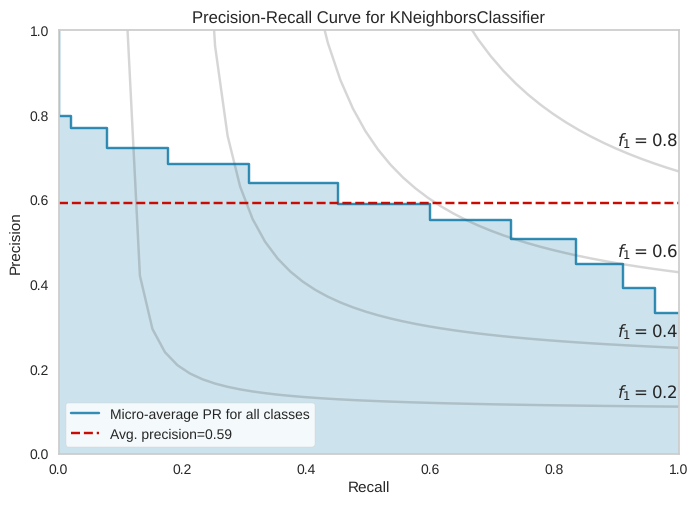

In [7]:
model_knn = \
    Pipeline([
        ('preprocessor',pr_oh),
        ('estimator', KNeighborsClassifier(n_neighbors=10))
    ])

model_knn.fit(X_train, y_train)


print(classification_report(y_test, model_knn.predict(X_test),
                            target_names=target_names))

auc_scores_simple_knn = multiclass_roc_auc_score_and_plot(model_knn, X_test, y_test, model_name='Simple KNN')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = model_knn,
                            is_fitted = True);



precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = model_knn,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

Below I create a pipeline with a **simple Decision Tree Classifier**:

              precision    recall  f1-score   support

        Good       0.38      0.40      0.39       483
        Poor       0.46      0.45      0.45       720
    Standard       0.58      0.57      0.57      1297

    accuracy                           0.50      2500
   macro avg       0.47      0.47      0.47      2500
weighted avg       0.50      0.50      0.50      2500



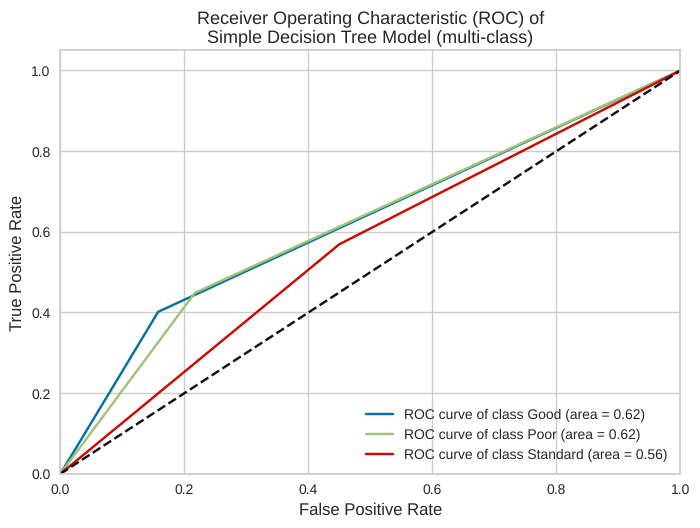

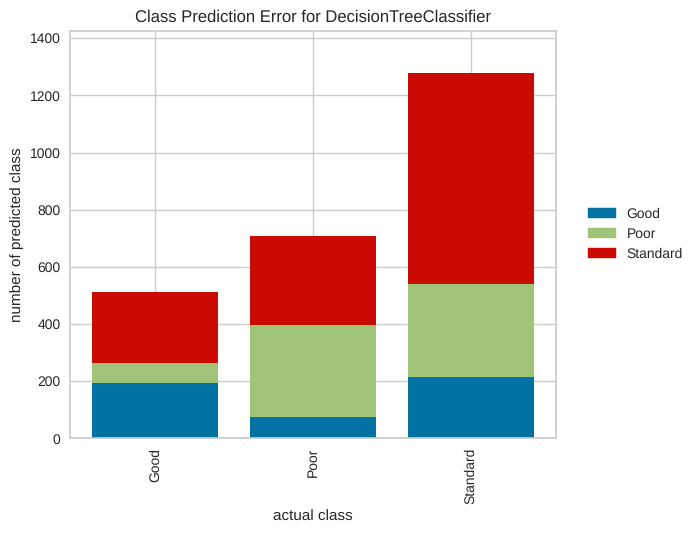

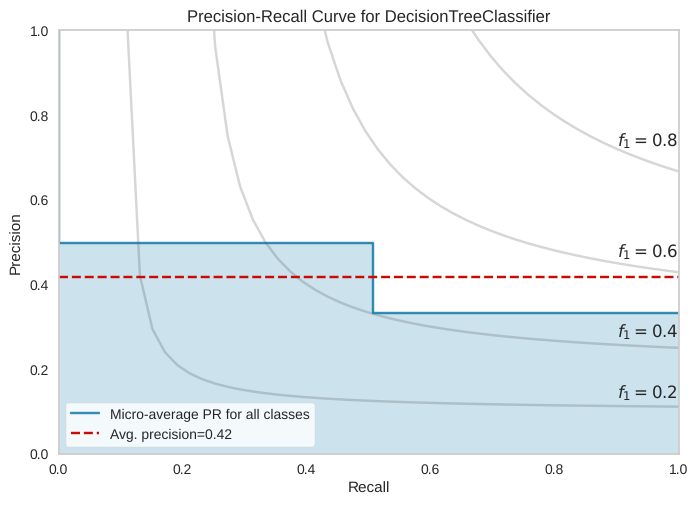

In [8]:
model_dtr = \
    Pipeline([
        ('preprocessor',pr_ord),
        ('estimator', DecisionTreeClassifier(random_state=42))
    ])

model_dtr.fit(X_train, y_train)


print(classification_report(y_test, model_dtr.predict(X_test),
                            target_names=target_names))

auc_scores_simple_dtr = multiclass_roc_auc_score_and_plot(model_dtr, X_test, y_test, model_name='Simple Decision Tree')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = model_dtr,
                            is_fitted = True);



precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = model_dtr,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

Below I create a pipeline with a **simple SVM Classifier**:
**Important Note**: For SVM Classifiers I will keep the maximum threshold iterations to 10000 (computational constraint of my local machine)

              precision    recall  f1-score   support

        Good       0.48      0.62      0.54       483
        Poor       0.61      0.56      0.59       720
    Standard       0.67      0.63      0.65      1297

    accuracy                           0.61      2500
   macro avg       0.59      0.60      0.59      2500
weighted avg       0.62      0.61      0.61      2500



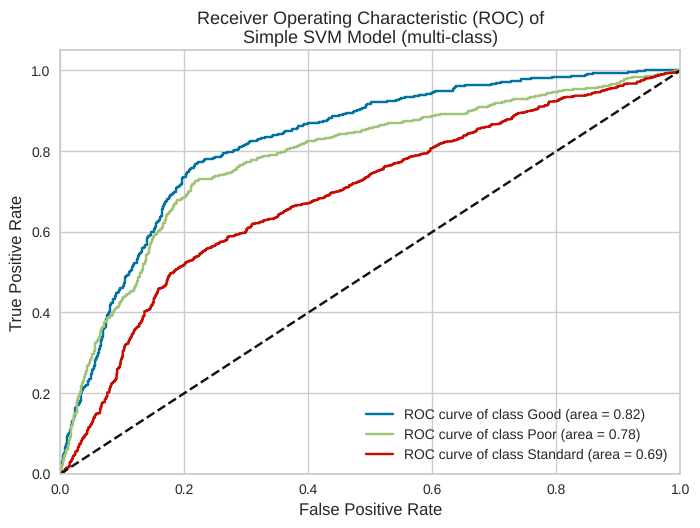

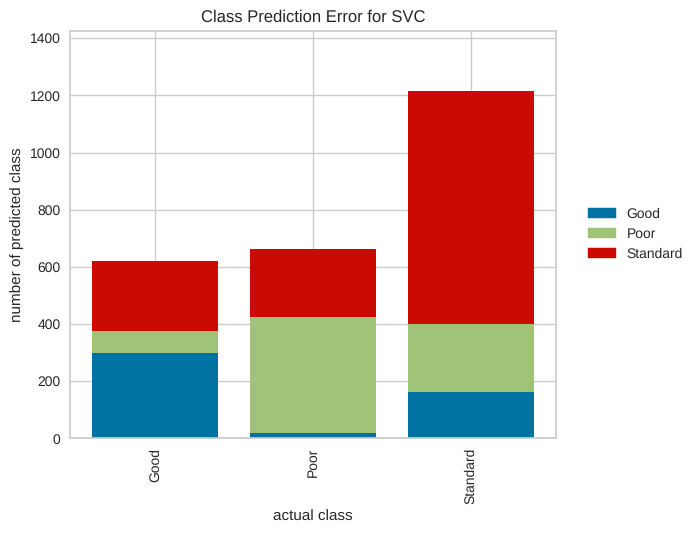

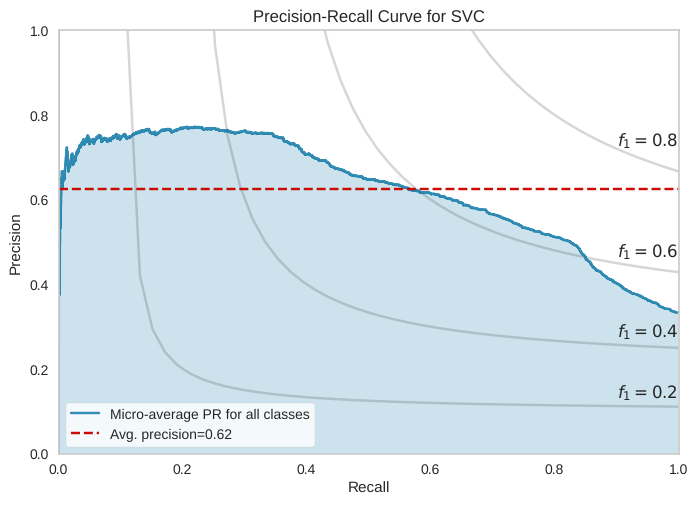

In [9]:
model_svm = \
    Pipeline([
        ('preprocessor',pr_oh),
        ('estimator', SVC(random_state= 42,
                          probability= True,
                          coef0= 1,
                          max_iter= 10_000
                         ) )
    ])

model_svm.fit(X_train, y_train)


print(classification_report(y_test, model_svm.predict(X_test),
                            target_names= target_names))

auc_scores_simple_svm = multiclass_roc_auc_score_and_plot(model_svm, X_test, y_test, model_name='Simple SVM')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = model_svm,
                            is_fitted = True);



precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = model_svm,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

#### Using GridSearchCV with the above Classifiers to optimise models' hyperparameters

The [**scoring metrics**](https://scikit-learn.org/stable/modules/model_evaluation.html) I can use on **GridSearchCV** are demonstrated below. I will use ROC curves and AUC score to evaluate my initial models. 

Scoring Metrics available


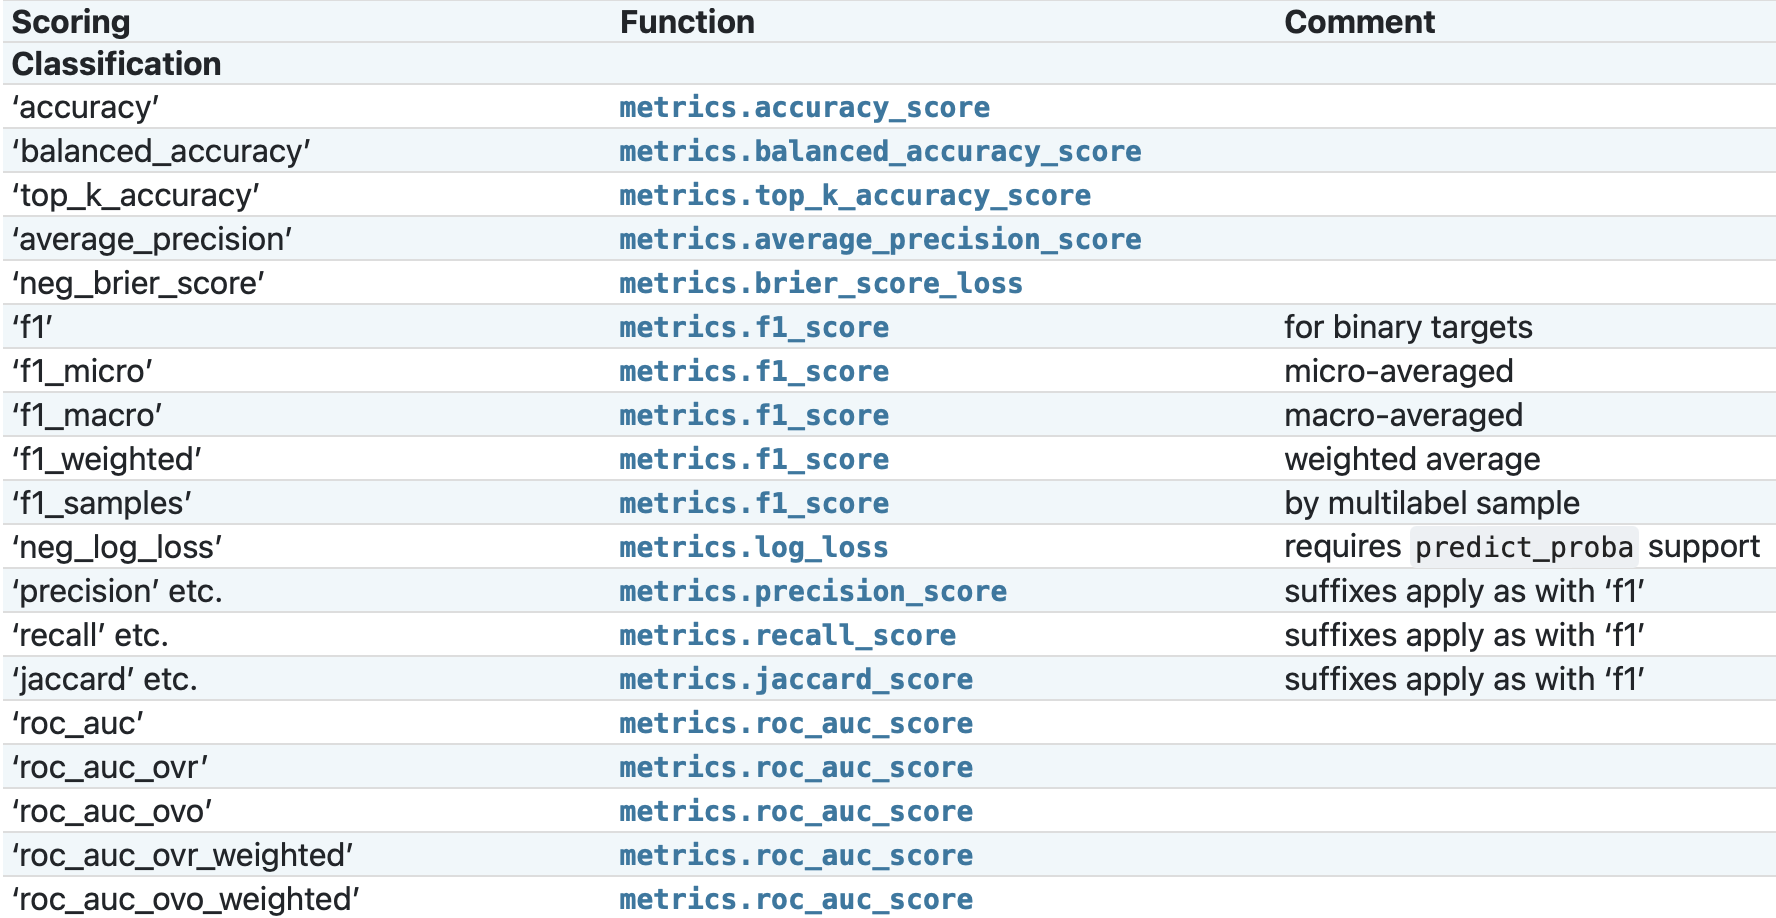

In [10]:
# The score to be used on Grid Searchers:
score_metric_used = 'roc_auc_ovr'

print('Scoring Metrics available')
Image("images/scoring_metrics.png")

Below I use the GridSearchCV algorithm on **Logistic Regression** Pipeline.

Firstly, a set of parameters (params_grid) for the model is defined. Then, I construct estimators for every possible combination of the given hyperparameters in params_grid. The best combination is chosen based on the evaluation metric (roc_auc_ovr). 

It is worth mentioning that during the training of every estimator the K-fold Cross Validation strategy (by default K=5) is used to mitigate the risk of overfitting during the training phase.

In [11]:
# set of parameters:
lr_params = {'estimator__C':[0.1,1,10,100,150,200,250,300,500,1000],
             'estimator__max_iter':[300, 1000, 10000]
             }
#applying grid search algorithm:
grid_lr = \
    GridSearchCV(estimator= model_lr,
                 param_grid= lr_params,
                 scoring= score_metric_used,
                 return_train_score= True
                 ).fit(X_train, y_train)

And I plot/export the metrics below:

              precision    recall  f1-score   support

        Good       0.50      0.51      0.51       483
        Poor       0.54      0.35      0.42       720
    Standard       0.59      0.70      0.64      1297

    accuracy                           0.56      2500
   macro avg       0.54      0.52      0.52      2500
weighted avg       0.56      0.56      0.55      2500



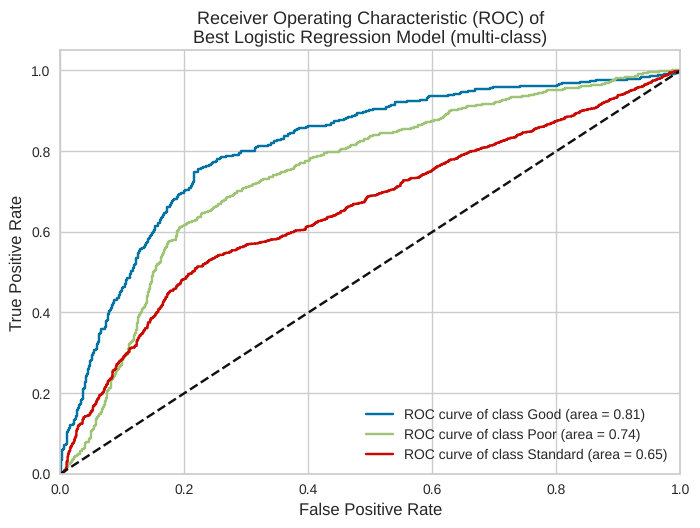

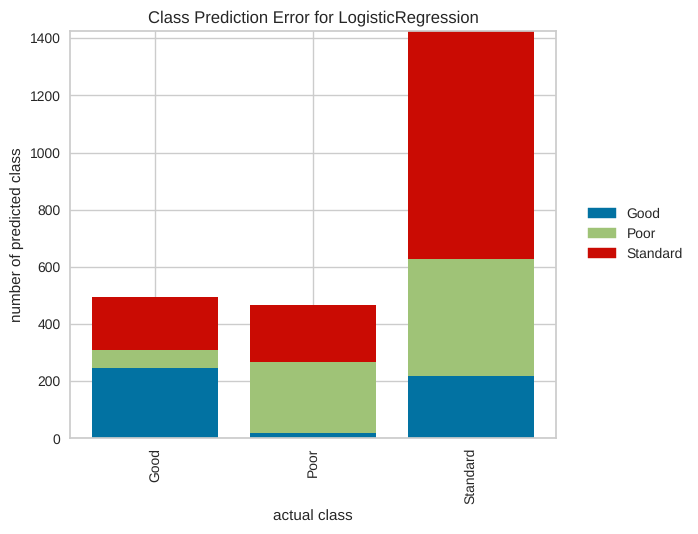

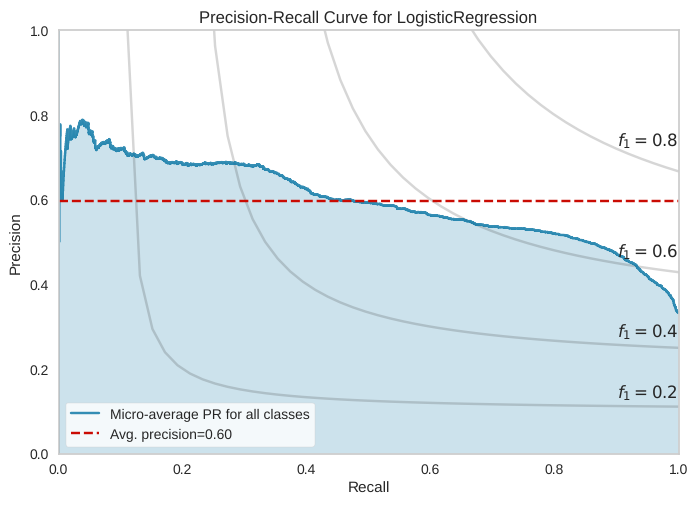

In [12]:
print(classification_report(y_test,
                            grid_lr.best_estimator_.predict(X_test),
                            target_names=target_names)
      )

auc_scores_lr = multiclass_roc_auc_score_and_plot(grid_lr.best_estimator_,
                                               X_test, y_test,
                                               model_name='Best Logistic Regression')

class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_lr.best_estimator_,
                            is_fitted = True);

precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_lr.best_estimator_,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

Similarly, with the above logic, below I use the GridSearchCV on the **KNN** Pipeline:

**Note**:You can refer to the following [Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.distance_metrics.html#sklearn.metrics.pairwise.distance_metrics) for the available distances/metrics to choose for KNN Classifier.

In [13]:
knn_params = {'estimator__n_neighbors':[3, 5, 7, 19],
             'estimator__weights':['uniform', 'distance'],
              'estimator__metric':['minkowski','euclidean','manhattan','cosine']
             }

grid_knn = \
    GridSearchCV(estimator= model_knn,
                 param_grid= knn_params,
                 scoring= score_metric_used,
                 return_train_score= True,
                 n_jobs = 4
                 ).fit(X_train, y_train)

And I plot/export the metrics below:

              precision    recall  f1-score   support

        Good       0.51      0.48      0.50       483
        Poor       0.62      0.51      0.56       720
    Standard       0.64      0.71      0.67      1297

    accuracy                           0.61      2500
   macro avg       0.59      0.57      0.58      2500
weighted avg       0.61      0.61      0.61      2500



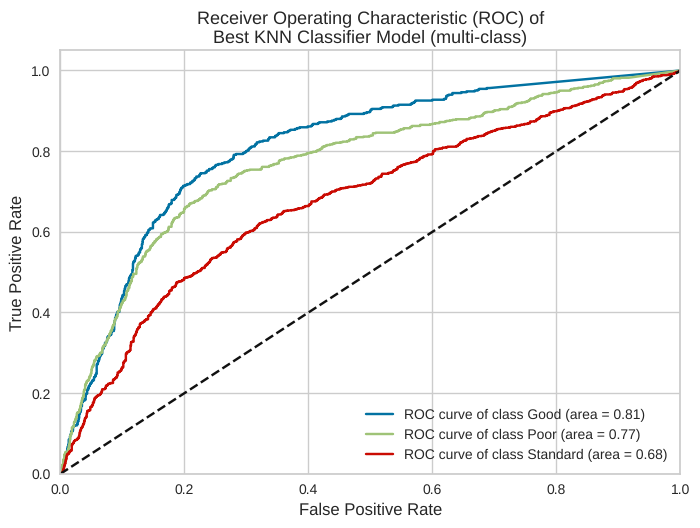

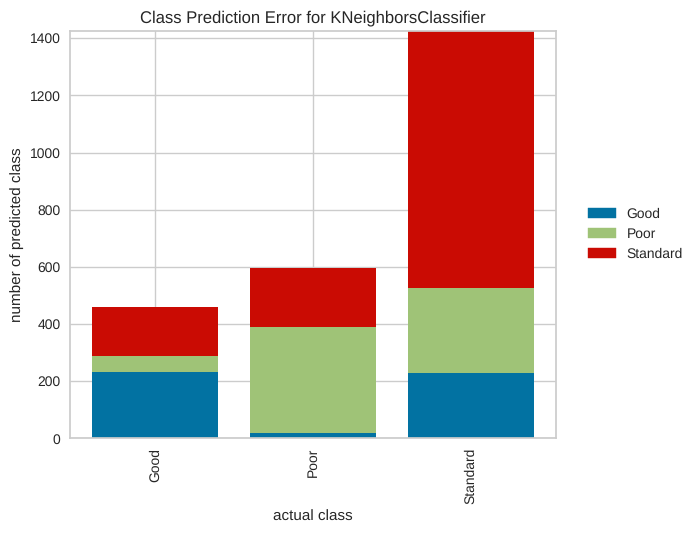

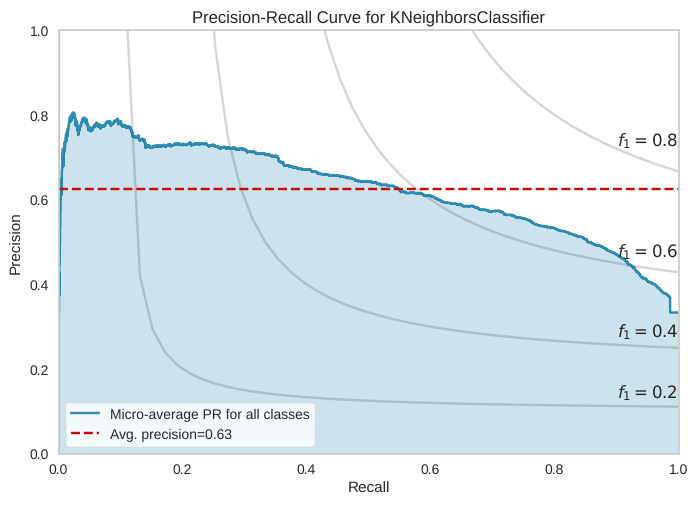

In [14]:
print(classification_report(y_test, grid_knn.best_estimator_.predict(X_test),
                            target_names=target_names)
      )


auc_scores_knn = multiclass_roc_auc_score_and_plot(grid_knn.best_estimator_,
                                               X_test, y_test,
                                               model_name='Best KNN Classifier')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_knn.best_estimator_,
                            is_fitted = True);

precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_knn.best_estimator_,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

Below I use the GridSearchCV on **Decision Tree** Pipeline:

In [15]:
dtr_params = {'estimator__criterion':['gini', 'entropy', 'log_loss'],
              'estimator__splitter':['best', 'random'],
              'estimator__min_samples_split':[2,4,6],
              'estimator__min_samples_leaf':[1,2,3,4,5],
              'estimator__max_features':[None, 'sqrt', 'log2'],
              'estimator__max_depth':[None,3, 10, 20 ,30, 100]
              }

grid_dtr = \
    GridSearchCV(estimator= model_dtr,
                 param_grid= dtr_params,
                 scoring= score_metric_used,
                 return_train_score= True,
                 n_jobs = 4
                 ).fit(X_train, y_train)

And I plot/export the metrics below:

              precision    recall  f1-score   support

        Good       0.48      0.68      0.56       483
        Poor       0.61      0.54      0.57       720
    Standard       0.69      0.62      0.65      1297

    accuracy                           0.61      2500
   macro avg       0.59      0.61      0.60      2500
weighted avg       0.62      0.61      0.61      2500



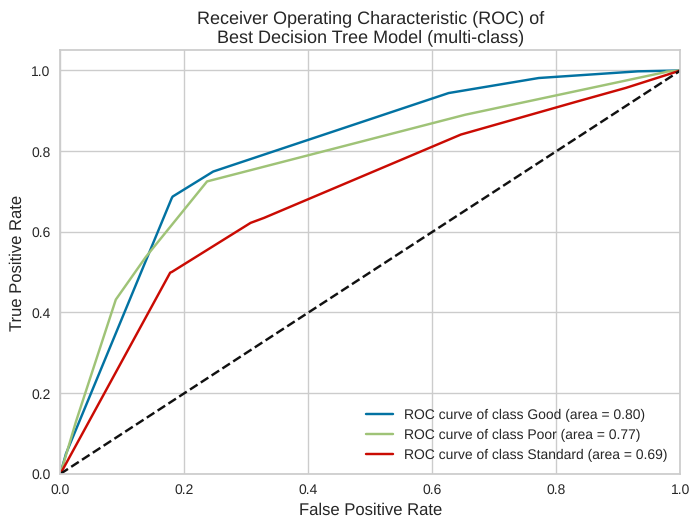

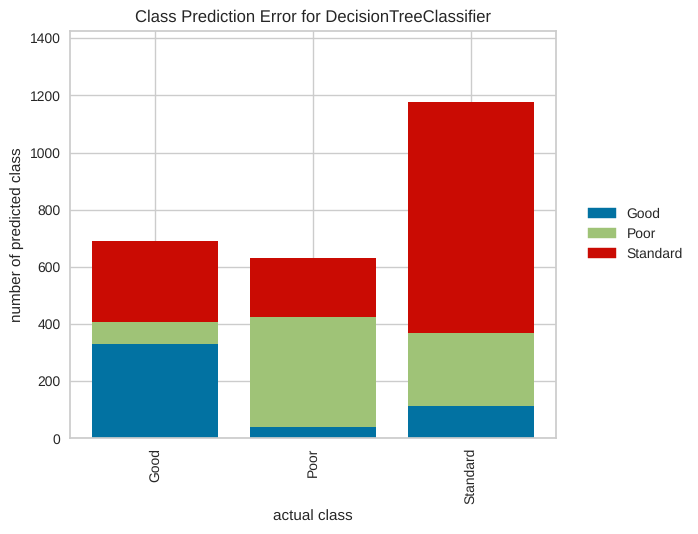

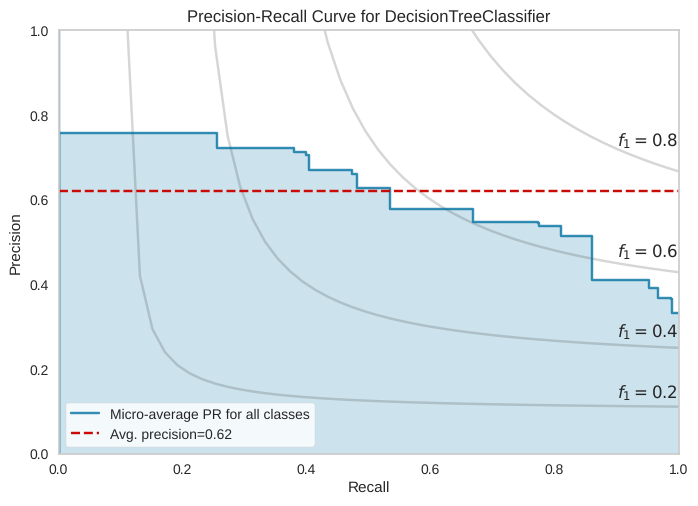

In [16]:
print(classification_report(y_test, grid_dtr.best_estimator_.predict(X_test),
                            target_names=target_names)
      )


auc_scores_dtr = multiclass_roc_auc_score_and_plot(grid_dtr.best_estimator_,
                                               X_test, y_test,
                                               model_name='Best Decision Tree')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_dtr.best_estimator_,
                            is_fitted = True);

precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_dtr.best_estimator_,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);


Below I use the GridSearchCV on **SVM** Pipeline:

In [17]:
from warnings import simplefilter
from sklearn.exceptions import ConvergenceWarning
simplefilter("ignore", category=ConvergenceWarning)

svm_params = {'estimator__C':[1, 10, 100],
              'estimator__kernel':['rbf', 'linear', 'poly', 'sigmoid'],
              'estimator__gamma':['scale','auto'],
              'estimator__class_weight':[None, 'balanced']
              }

grid_svm = \
    GridSearchCV(estimator= model_svm,
                 param_grid= svm_params,
                 scoring= score_metric_used,
                 return_train_score= True,
                 cv = 2, # because of computational restrictions on my local machine I set the cv = 2
                 n_jobs = 4
                 ).fit(X_train, y_train)

# Produces warnings because of max_iter =  10_000. 
# Unfortunately, I cannot change this setting due to computational constraints of my local machine.

/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


...

/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/tmp/claude-0/-home-user-Credit-Score-Classification-Project/f671f488-60f4-5814-ab03-4e4ece6cdca6/scratchpad/py311/lib/python3.11/site-packages/sklearn/svm/_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


And I plot/export the metrics below:

              precision    recall  f1-score   support

        Good       0.47      0.75      0.58       483
        Poor       0.58      0.70      0.63       720
    Standard       0.75      0.50      0.60      1297

    accuracy                           0.60      2500
   macro avg       0.60      0.65      0.60      2500
weighted avg       0.65      0.60      0.60      2500



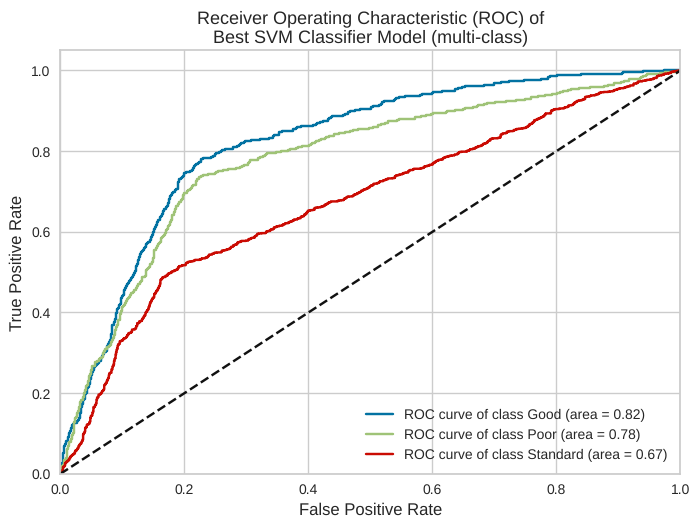

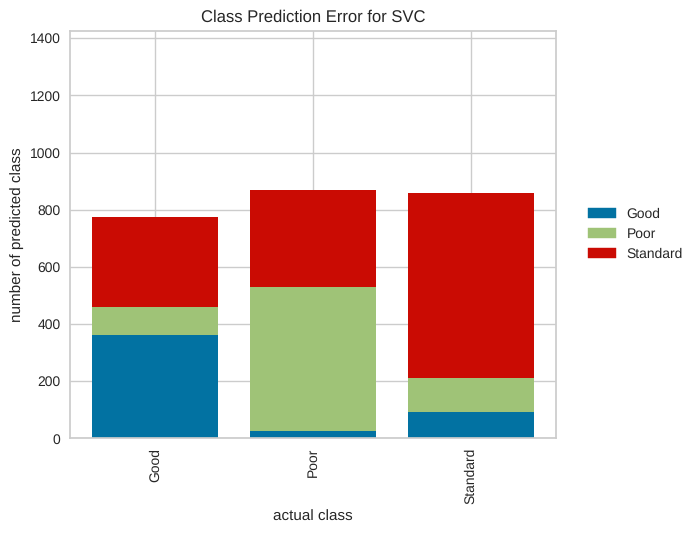

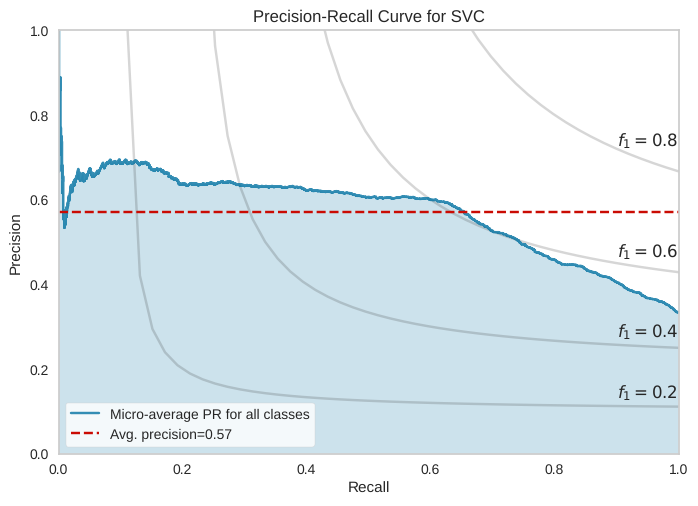

In [18]:
print(classification_report(y_test, grid_svm.best_estimator_.predict(X_test),
                            target_names=target_names)
      )


auc_scores_svm = multiclass_roc_auc_score_and_plot(grid_svm.best_estimator_,
                                                   X_test, y_test,
                                                   model_name='Best SVM Classifier')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_svm.best_estimator_,
                            is_fitted = True);

precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_svm.best_estimator_,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

### Additional Models

I add some extra models to the analysis. More specifically, I will use:
- **Random Forest Classifier**
- **Gradient Boosting Classifier**

In [19]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

Below, I create a pipeline with a **simple Random Forest Classifier**:

              precision    recall  f1-score   support

        Good       0.50      0.48      0.49       483
        Poor       0.60      0.57      0.59       720
    Standard       0.64      0.67      0.65      1297

    accuracy                           0.60      2500
   macro avg       0.58      0.57      0.58      2500
weighted avg       0.60      0.60      0.60      2500



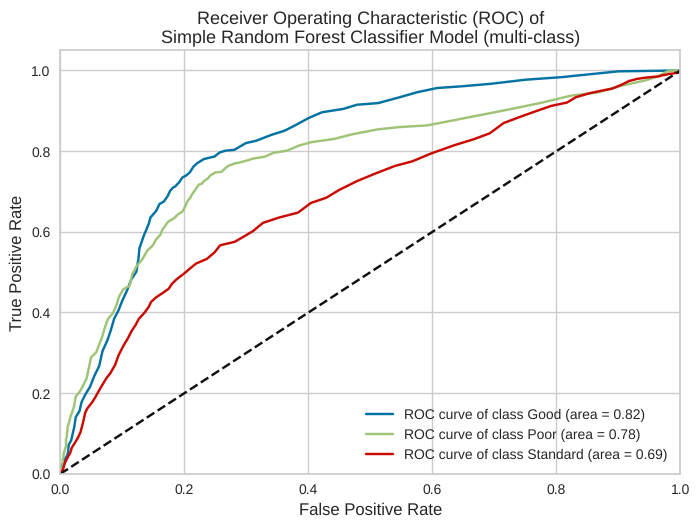

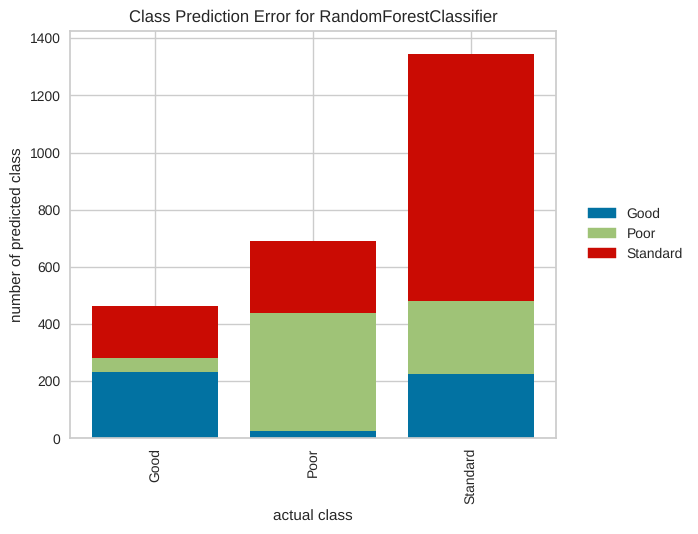

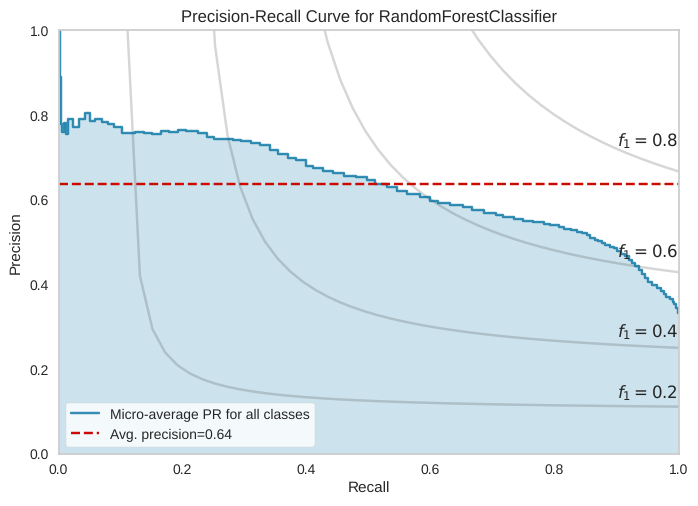

In [20]:
model_ranf = \
    Pipeline([
        ('preprocessor',pr_ord), # it uses tree models, so I do not use One Hot Encoding
        ('estimator', RandomForestClassifier(random_state= 42, oob_score = False) )
    ])

model_ranf.fit(X_train, y_train)


print(classification_report(y_test, model_ranf.predict(X_test),
                            target_names= target_names))

auc_scores_simple_ranf = multiclass_roc_auc_score_and_plot(model_ranf,
                                                           X_test, y_test,
                                                           model_name='Simple Random Forest Classifier')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = model_ranf,
                            is_fitted = True);



precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = model_ranf,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

Below, I create a pipeline with a **simple Gradient Boosting Classifier**:

              precision    recall  f1-score   support

        Good       0.51      0.53      0.52       483
        Poor       0.61      0.58      0.60       720
    Standard       0.66      0.67      0.66      1297

    accuracy                           0.62      2500
   macro avg       0.59      0.59      0.59      2500
weighted avg       0.62      0.62      0.62      2500



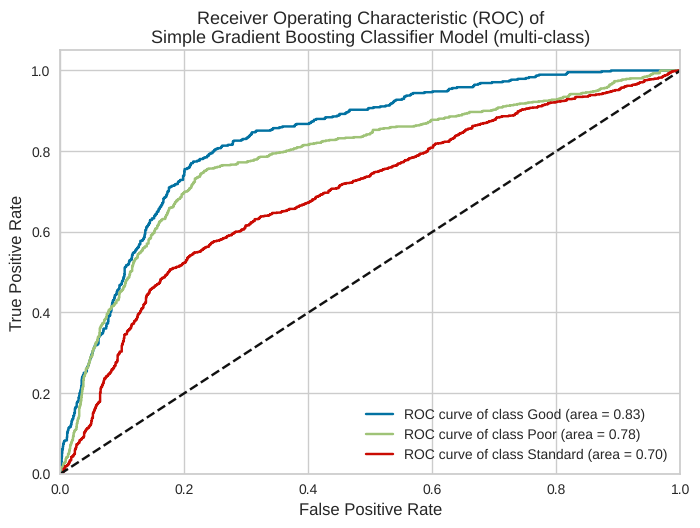

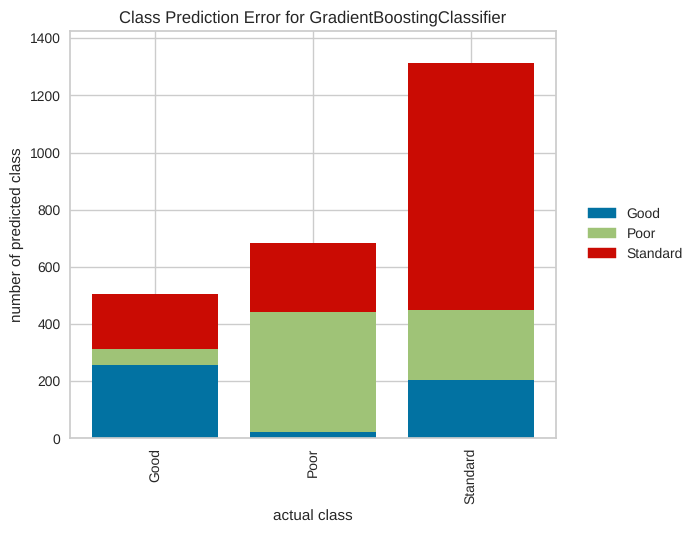

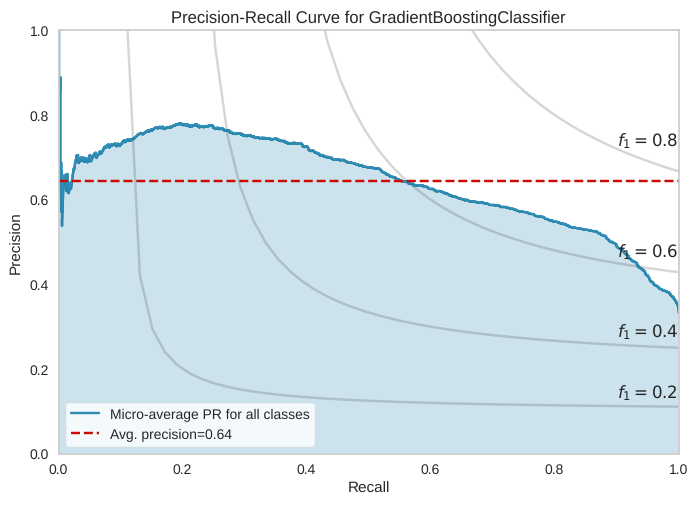

In [21]:
model_gbc = \
    Pipeline([
        ('preprocessor',pr_ord), # it uses tree models, so I do not use One Hot Encoding
        ('estimator', GradientBoostingClassifier(random_state= 42) )
    ])

model_gbc.fit(X_train, y_train)


print(classification_report(y_test, model_gbc.predict(X_test),
                            target_names= target_names))

auc_scores_simple_gbc = multiclass_roc_auc_score_and_plot(model_gbc,
                                                          X_test, y_test,
                                                          model_name= 'Simple Gradient Boosting Classifier')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = model_gbc,
                            is_fitted = True);



precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = model_gbc,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

#### Using GridSearchCV on the above models
Below I use the GridSearchCV on **Random Forest Classifier** Pipeline:

In [22]:
ranf_params = {'estimator__n_estimators':[1, 10, 100],
              'estimator__criterion':['gini', 'entropy'],
              #'estimator__ccp_alpha': [0.0, 0.05, 0.2], # commented to reduce the dimensions of param_grid
              'estimator__max_features':[None, 'sqrt', 'log2'],
              'estimator__max_depth':[3, 10, 20]
              }

grid_ranf = \
    GridSearchCV(estimator= model_ranf,
                 param_grid= ranf_params,
                 scoring= score_metric_used,
                 return_train_score= True,
                 n_jobs = 4
                 ).fit(X_train, y_train)

And I plot/export the metrics below:

              precision    recall  f1-score   support

        Good       0.51      0.63      0.56       483
        Poor       0.62      0.59      0.60       720
    Standard       0.69      0.64      0.66      1297

    accuracy                           0.62      2500
   macro avg       0.60      0.62      0.61      2500
weighted avg       0.63      0.62      0.63      2500



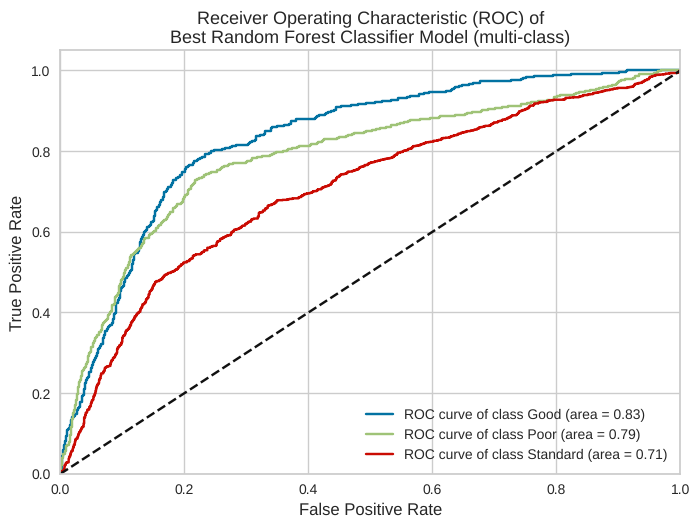

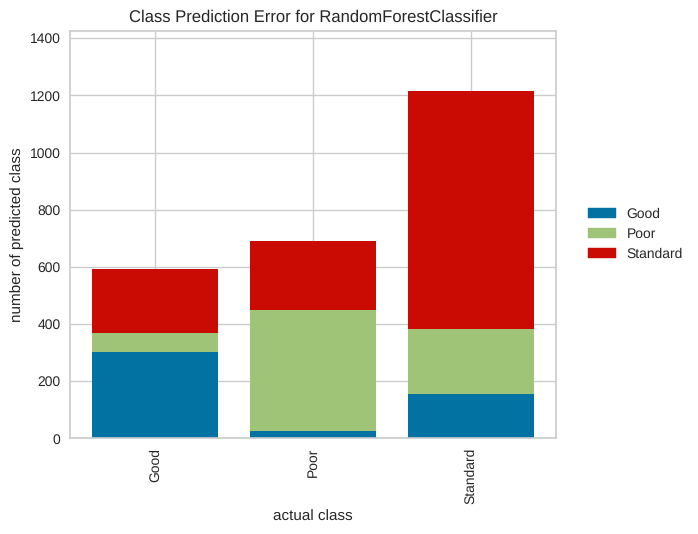

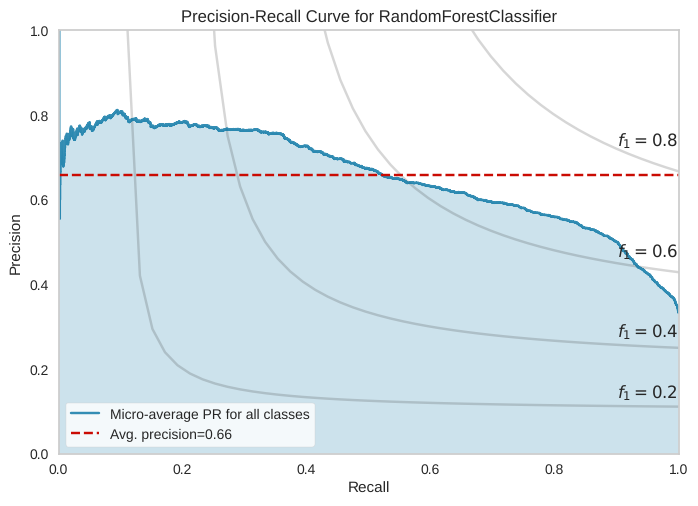

In [23]:
print(classification_report(y_test, grid_ranf.best_estimator_.predict(X_test),
                            target_names=target_names)
      )


auc_scores_ranf = multiclass_roc_auc_score_and_plot(grid_ranf.best_estimator_,
                                                   X_test, y_test,
                                                   model_name='Best Random Forest Classifier')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_ranf.best_estimator_,
                            is_fitted = True);

precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_ranf.best_estimator_,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

Below I use the GridSearchCV on **Gradient Boosting Classifier** Pipeline:

In [24]:
gbc_params = {'estimator__learning_rate':[0.1, 1],
               'estimator__n_estimators':[10, 100],
               'estimator__criterion':['friedman_mse', 'squared_error'], # commented to reduce the dimensions of param_grid
               'estimator__ccp_alpha': [0.0, 0.05, 0.2],
               'estimator__max_features':['sqrt', 'log2'],
               'estimator__max_depth':[3, 10, 20]
               }

grid_gbc = \
    GridSearchCV(estimator= model_gbc,
                 param_grid= gbc_params,
                 scoring= score_metric_used,
                 return_train_score= True,
                 n_jobs = 4
                 ).fit(X_train, y_train)

And I plot/export the metrics below:

              precision    recall  f1-score   support

        Good       0.51      0.52      0.52       483
        Poor       0.62      0.57      0.60       720
    Standard       0.65      0.68      0.66      1297

    accuracy                           0.62      2500
   macro avg       0.60      0.59      0.59      2500
weighted avg       0.62      0.62      0.62      2500



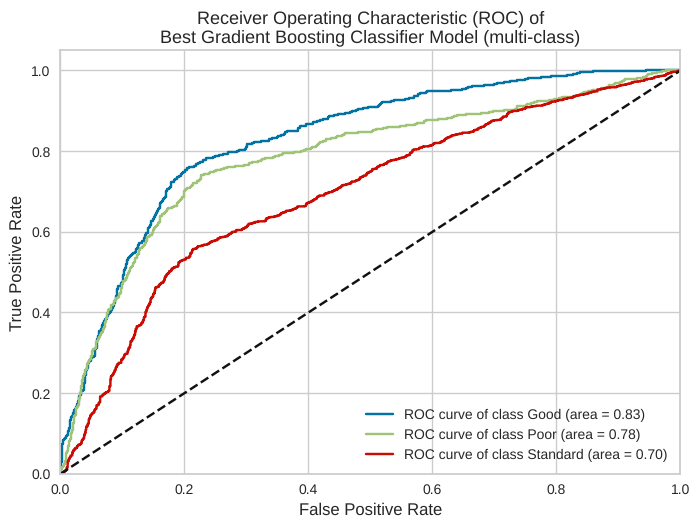

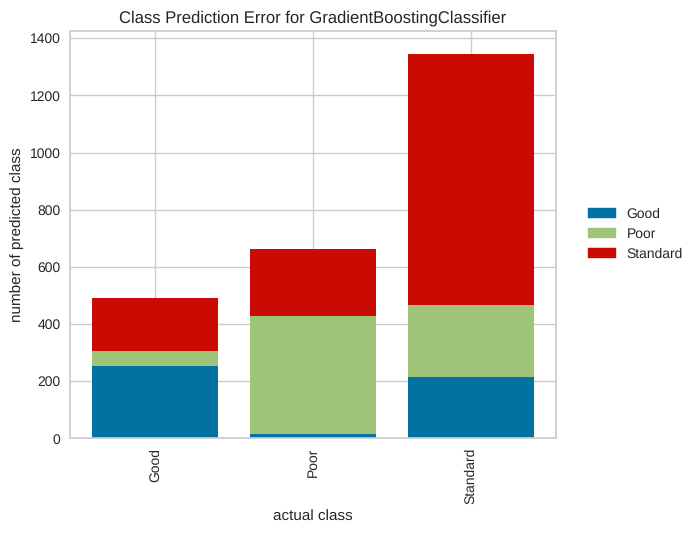

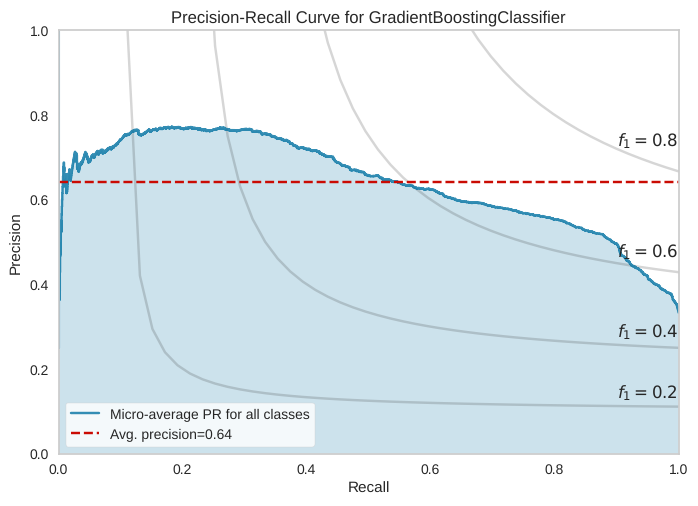

In [25]:
print(classification_report(y_test, grid_gbc.best_estimator_.predict(X_test),
                            target_names=target_names)
      )


auc_scores_gbc = multiclass_roc_auc_score_and_plot(grid_gbc.best_estimator_,
                                                    X_test, y_test,
                                                    model_name='Best Gradient Boosting Classifier')


class_prediction_error_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_gbc.best_estimator_,
                            is_fitted = True);

precision_recall_curve_plot(X_train, y_train, X_test, y_test,
                            estimator = grid_gbc.best_estimator_,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

Random Forest and Gradient Boosting Classifiers show the best overall results. Below, the results of the optimised / tuned models are demonstrated:

In [26]:
grid_models = \
[grid_lr,
grid_knn,
grid_dtr,
grid_svm,
grid_ranf,
grid_gbc]



model_names = \
['Logistic Regression',
 'KNN Classifier',
 'Decision Tree Classifier',
 'SVM Classifier',
 'Random Forest Classifier',
 'Gradient Boosting Classifier']


df_metrics = \
all_models_metrics(grid_models = grid_models,
                   model_names = model_names,
                   X_train = X_train, 
                   X_test = X_test,
                   y_train = y_train,
                   y_test = y_test)

In [27]:
df_metrics

,training_time,train_accuracy,test_accuracy,recall micro-average,precision micro-average,f1_score micro-average
Logistic Regression,0.053173,0.5620,0.5636,0.5636,0.5636,0.5636
KNN Classifier,0.026619,1.0000,0.6088,0.6088,0.6088,0.6088
Decision Tree Classifier,0.029510,0.5987,0.6096,0.6096,0.6096,0.6096
SVM Classifier,5.828328,0.6036,0.6040,0.6040,0.6040,0.6040
Random Forest Classifier,3.503165,0.7466,0.6244,0.6244,0.6244,0.6244
Gradient Boosting Classifier,2.086625,0.6472,0.6176,0.6176,0.6176,0.6176


According to the above results and ROC curves (AUC scores):
- Random Forests and Gradient Boosting Classifiers are promising (in terms of f1-score).
- As a result I will try to increase the input data to increase the models' performance.

Below I will insert all the observation (100k) to the models. Furthermore, I will add more features, specifically:
- Num_Bank_Accounts
- Num_of_Loan
- Changed_Credit_Limit

The decision on these additions was based on the correlations heatmap indicated on **Notebook 2**.

**Important Note**:
In multi-class classification, when using the average="micro" parameter, the values of accuracy, precision, and recall are the same. But why? An explanation is demonstrated below:

Micro-Averaging:
- In micro-averaging, we sum the true positives (TP), false positives (FP) and false negatives (FN) of all the classes before calculating the metrics.
- The formula for micro-averaged precision and recall is as follows:
-- Micro-averaged precision = ΣTP / (ΣTP + ΣFP)
-- Micro-averaged recall = ΣTP / (ΣTP + ΣFN)
- Every wrong prediction is a false positive for the predicted class and a false negative for the true class, so ΣFP = ΣFN (the number of wrong predictions). Since the denominators are the same for both precision and recall, they yield identical values.

Explanation:
- ΣTP is the number of correct predictions, so ΣTP + ΣFP (= ΣTP + ΣFN) is the total number of samples (denoted as ttl_samples).

- In other words, the formula becomes:
Micro-averaged precision = Micro-averaged recall = ΣTP / ttl_samples = accuracy

**Since the denominators equal the total number of samples, the micro-averaged precision and recall (and therefore the f1 score) become the same as the accuracy**.

#### Increasing datasets' dimensions
Below I add the above-mentioned features and all the dataset's observations (100k):

In [28]:
# included features:
included_features_v2 = \
    ['Customer_ID',
     'Age',
     'Annual_Income',
     'Outstanding_Debt',
     'Total_EMI_per_month',
     'Delay_from_due_date',
     'Num_of_Delayed_Payment',
     'Credit_Utilization_Ratio',
     'Payment_Behaviour',
     'Credit_Mix',
     'Payment_of_Min_Amount',
     'Occupation',
     'Num_Bank_Accounts', #newly added
     'Num_of_Loan', #newly added
     'Changed_Credit_Limit', #newly added
     'Credit_Score']

# importing dataset:
data_v2 = pd.read_csv('data_clean/clean_dataset.csv')

# implementation of splitting strategy:
X_v2 = data_v2[included_features_v2].drop(columns=['Customer_ID', 'Credit_Score'])
y_v2 = data_v2['Credit_Score']

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = \
    train_test_split(X_v2, y_v2,
                     random_state=42,
                     test_size=0.2,  
                     stratify=y_v2) #stratified split


target_names = ['Good', 'Poor', 'Standard'] # needed for classification report

#check
X_v2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Age                       100000 non-null  float64
 1   Annual_Income             100000 non-null  float64
 2   Outstanding_Debt          100000 non-null  float64
 3   Total_EMI_per_month       100000 non-null  float64
 4   Delay_from_due_date       100000 non-null  float64
 5   Num_of_Delayed_Payment    100000 non-null  float64
 6   Credit_Utilization_Ratio  100000 non-null  float64
 7   Payment_Behaviour         100000 non-null  object 
 8   Credit_Mix                100000 non-null  object 
 9   Payment_of_Min_Amount     100000 non-null  object 
 10  Occupation                100000 non-null  object 
 11  Num_Bank_Accounts         100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Changed_Credit_Limit      100000 non-null  fl

**Calculating the baseline accuracy on the new subset**:

In [29]:
print(f"Baseline accuracy: {y_test_v2.value_counts(normalize=True).max()*100:.2f}%\n\n")

Baseline accuracy: 53.17%




#### Creating, training and evaluating new models (Random Forests and Gradient Boosting Classifiers) on the bigger subset
In a similar way as the above approaches I will train and evaluate my new models on the new dataset. Below I construct a **Random Forest Classifier**:

              precision    recall  f1-score   support

        Good       0.73      0.75      0.74      3566
        Poor       0.77      0.80      0.78      5799
    Standard       0.81      0.79      0.80     10635

    accuracy                           0.78     20000
   macro avg       0.77      0.78      0.77     20000
weighted avg       0.78      0.78      0.78     20000



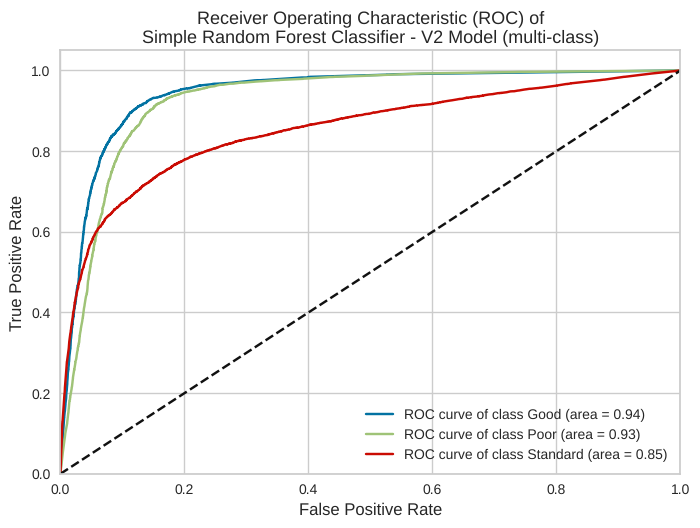

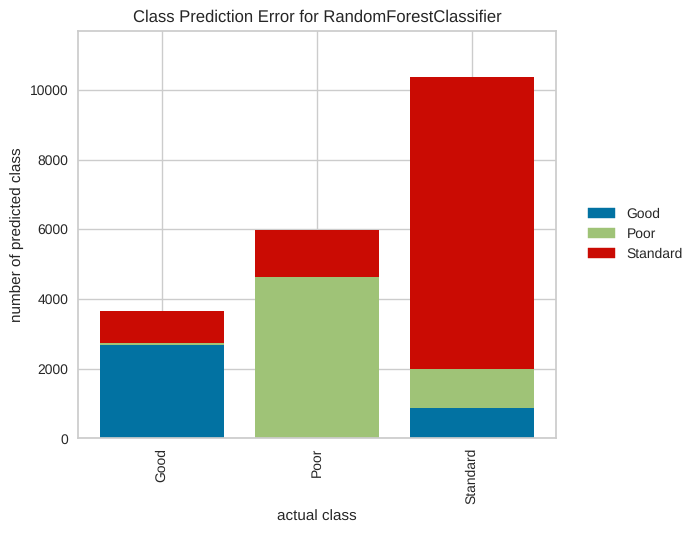

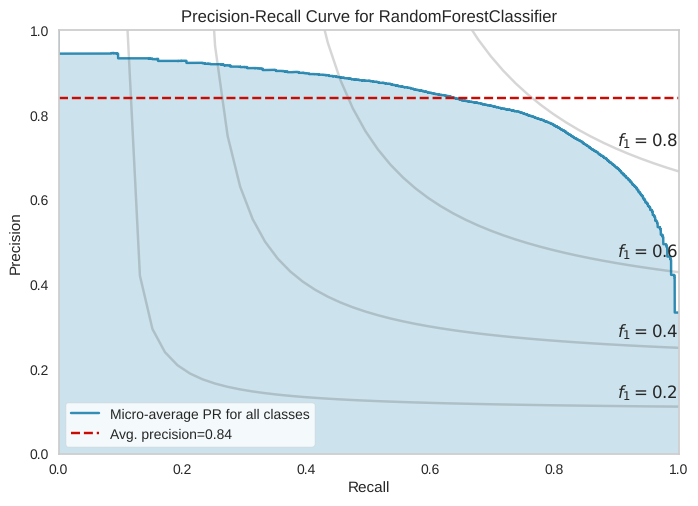

In [30]:
# new random forest model:
model_ranf_v2 = \
    Pipeline([
        ('preprocessor',pr_ord), # it uses tree models, so I do not use One Hot Encoding
        ('estimator', RandomForestClassifier(random_state= 42, oob_score = False) )
    ])

model_ranf_v2.fit(X_train_v2, y_train_v2)


print(classification_report(y_test_v2, model_ranf_v2.predict(X_test_v2),
                            target_names= target_names))

auc_scores_simple_ranf_v2 = multiclass_roc_auc_score_and_plot(model_ranf_v2,
                                                           X_test_v2, y_test_v2,
                                                           model_name='Simple Random Forest Classifier - V2')


class_prediction_error_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator = model_ranf_v2,
                            is_fitted = True);



precision_recall_curve_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator = model_ranf_v2,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

The above graphs demonstrate excellent results. I should also investigate **Gradient Boosting Classifier**.

              precision    recall  f1-score   support

        Good       0.52      0.80      0.63      3566
        Poor       0.67      0.67      0.67      5799
    Standard       0.79      0.66      0.72     10635

    accuracy                           0.69     20000
   macro avg       0.66      0.71      0.67     20000
weighted avg       0.71      0.69      0.69     20000



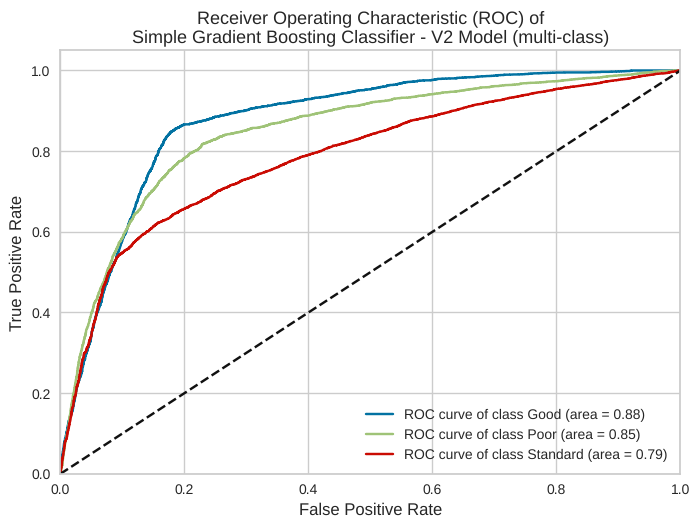

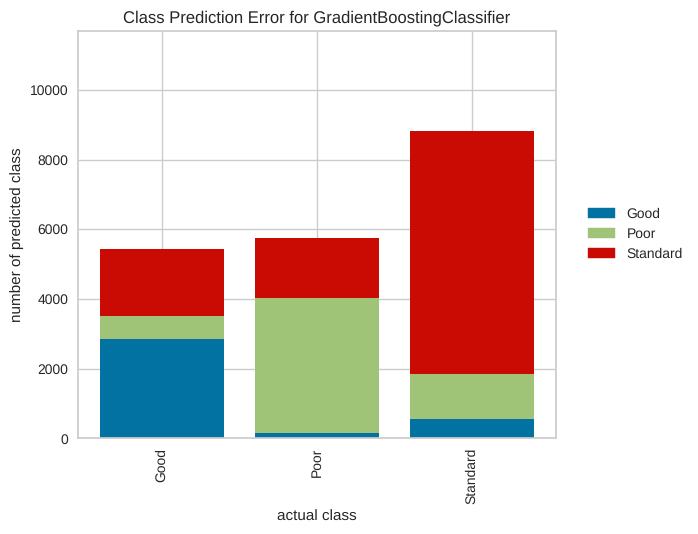

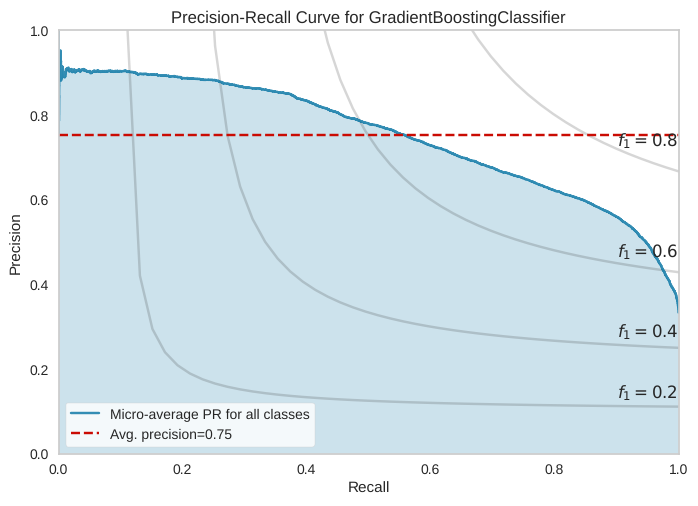

In [31]:
model_gbc_v2 = \
    Pipeline([
        ('preprocessor',pr_ord), # it uses tree models, so I do not use One Hot Encoding
        ('estimator', GradientBoostingClassifier(random_state= 42) )
    ])

model_gbc_v2.fit(X_train_v2, y_train_v2)


print(classification_report(y_test_v2, model_gbc_v2.predict(X_test_v2),
                            target_names= target_names))

auc_scores_simple_gbc_v2 = multiclass_roc_auc_score_and_plot(model_gbc_v2,
                                                          X_test_v2, y_test_v2,
                                                          model_name= 'Simple Gradient Boosting Classifier - V2')


class_prediction_error_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator = model_gbc_v2,
                            is_fitted = True);



precision_recall_curve_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator = model_gbc_v2,
                            line_per_class = False,
                            is_fitted = False,
                            plot_f1_curves=True,);

I will try to fine-tune the models through the GridSearchCV algorithm.
**Important Note** - Due to computational constraints of my local machine: 
- I will construct a parameters grid containing only three hyperparameters of the models.
- I will use a 3-fold cross validation during the grid searching (default is 5)

Creating the Random Forest Classifier - V2 using the GridSearchCV:

In [32]:
ranf_params_v2 = {'estimator__n_estimators': [50, 100, 150, 200],
               'estimator__criterion': ['gini', 'entropy'],
                'estimator__min_impurity_decrease':[0.0, 0.4]
               #'estimator__max_depth': [None, 20, 30] #commented to reduce the dimensions of params_grid
               }

grid_ranf_v2 = \
    GridSearchCV(estimator=model_ranf_v2,
                 param_grid=ranf_params_v2,
                 scoring=score_metric_used,
                 return_train_score=True,
                 n_jobs=4,
                 cv = 3
                 ).fit(X_train_v2, y_train_v2)

# check:
grid_ranf_v2.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('standardscaler',
                                                  StandardScaler(),
                                                  ['Age', 'Annual_Income',
                                                   'Outstanding_Debt',
                                                   'Total_EMI_per_month',
                                                   'Delay_from_due_date',
                                                   'Num_of_Delayed_Payment']),
                                                 ('ordinalencoder',
                                                  OrdinalEncoder(),
                                                  ['Credit_Mix',
                                                   'Payment_of_Min_Amount'])])),
                ('estimator',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

And plotting its results:

              precision    recall  f1-score   support

        Good       0.73      0.76      0.74      3566
        Poor       0.77      0.80      0.78      5799
    Standard       0.81      0.79      0.80     10635

    accuracy                           0.78     20000
   macro avg       0.77      0.78      0.77     20000
weighted avg       0.78      0.78      0.78     20000



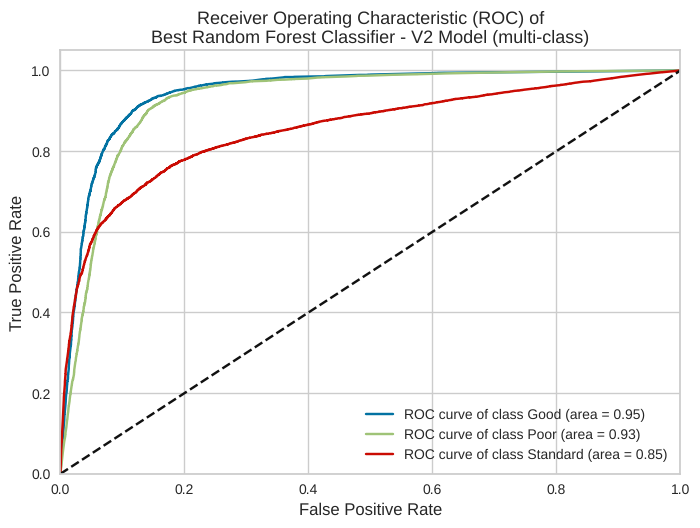

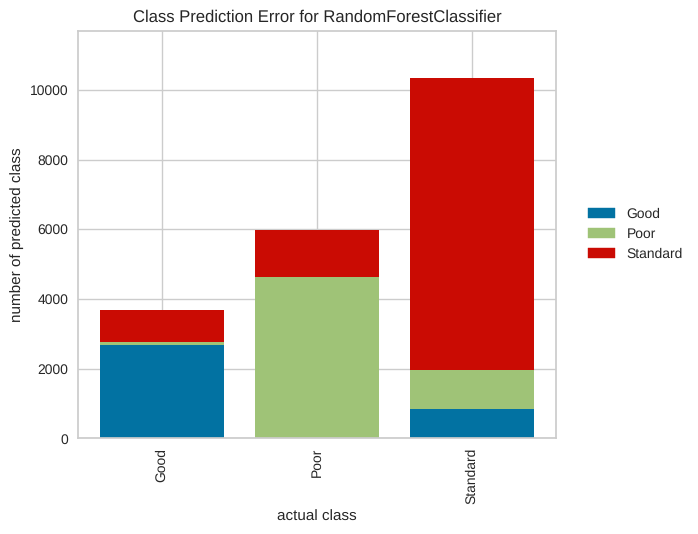

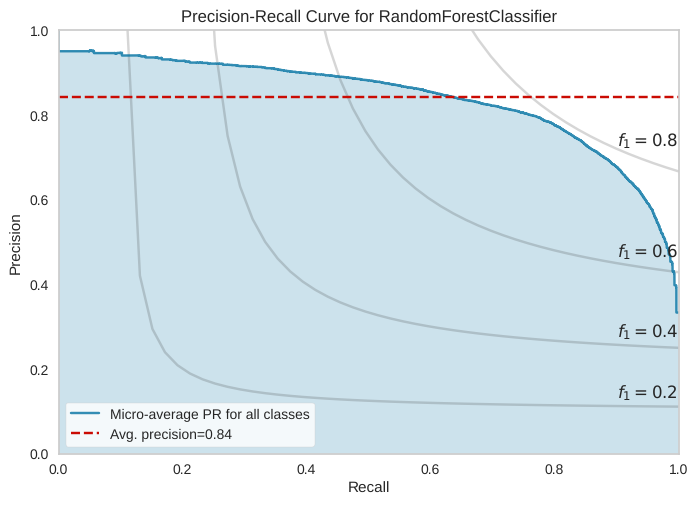

In [33]:
print(classification_report(y_test_v2, grid_ranf_v2.best_estimator_.predict(X_test_v2),
                            target_names=target_names)
      )

auc_scores_ranf_v2_2 = multiclass_roc_auc_score_and_plot(grid_ranf_v2.best_estimator_,
                                                    X_test_v2, y_test_v2,
                                                    model_name='Best Random Forest Classifier - V2')

class_prediction_error_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator=grid_ranf_v2.best_estimator_,
                            is_fitted=True);

precision_recall_curve_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator=grid_ranf_v2.best_estimator_,
                            line_per_class=False,
                            is_fitted=False,
                            plot_f1_curves=True, );

Creating the Gradient Boosting Classifier - V2 using the GridSearchCV:

In [34]:
gbc_params_v2 = {'estimator__learning_rate':[0.1, 1],
              'estimator__n_estimators':[50, 100, 150],
              'estimator__criterion':['friedman_mse', 'squared_error']
              }

grid_gbc_v2 = \
    GridSearchCV(estimator= model_gbc_v2,
                 param_grid= gbc_params_v2,
                 scoring= score_metric_used,
                 return_train_score= True,
                 n_jobs = 4,
                 cv = 3
                 ).fit(X_train_v2, y_train_v2)

grid_gbc_v2.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('standardscaler',
                                                  StandardScaler(),
                                                  ['Age', 'Annual_Income',
                                                   'Outstanding_Debt',
                                                   'Total_EMI_per_month',
                                                   'Delay_from_due_date',
                                                   'Num_of_Delayed_Payment']),
                                                 ('ordinalencoder',
                                                  OrdinalEncoder(),
                                                  ['Credit_Mix',
                                                   'Payment_of_Min_Amount'])])),
                ('estimator',
                 GradientBoostingClassifier(criterion='squared_error',
                                            learning_rate=1, n_estimators=150,
                                            random_state=42))])

And plotting its results:

              precision    recall  f1-score   support

        Good       0.65      0.72      0.68      3566
        Poor       0.73      0.73      0.73      5799
    Standard       0.78      0.75      0.77     10635

    accuracy                           0.74     20000
   macro avg       0.72      0.73      0.73     20000
weighted avg       0.74      0.74      0.74     20000



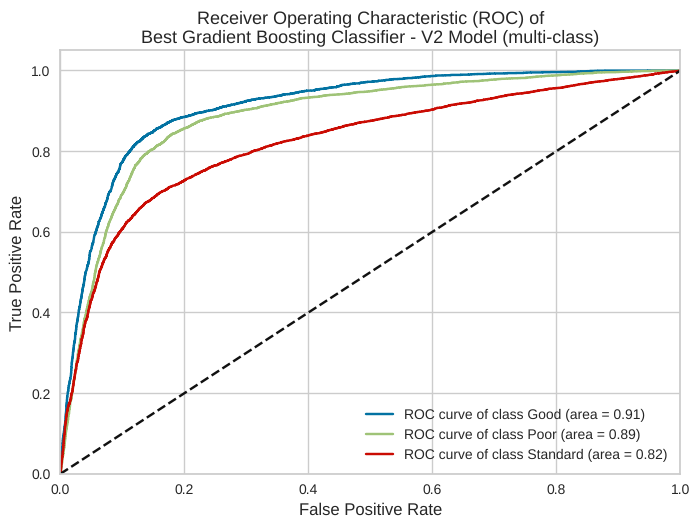

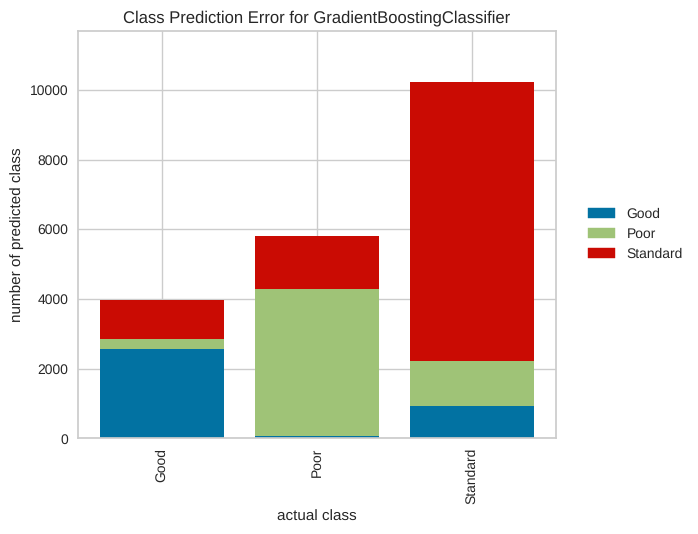

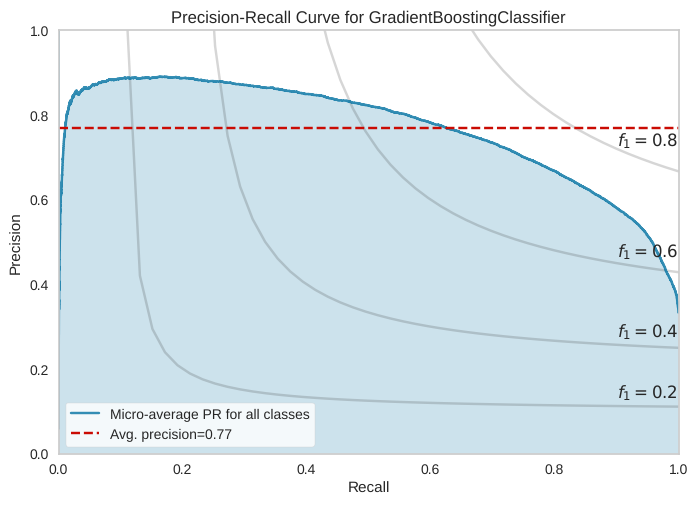

In [35]:
print(classification_report(y_test_v2, grid_gbc_v2.best_estimator_.predict(X_test_v2),
                            target_names=target_names)
      )

auc_scores_gbc_v2_2 = multiclass_roc_auc_score_and_plot(grid_gbc_v2.best_estimator_,
                                                         X_test_v2, y_test_v2,
                                                         model_name='Best Gradient Boosting Classifier - V2')

class_prediction_error_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator=grid_gbc_v2.best_estimator_,
                            is_fitted=True);

precision_recall_curve_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator=grid_gbc_v2.best_estimator_,
                            line_per_class=False,
                            is_fitted=False,
                            plot_f1_curves=True, );

In [36]:
grid_models_v2 = \
    [grid_ranf_v2,
     grid_gbc_v2]

model_names_v2 = \
    ['Random Forest Classifier - V2',
     'Gradient Boost Classifier - V2']


df_metrics_v2 = \
    all_models_metrics(grid_models = grid_models_v2,
                       model_names = model_names_v2,
                       X_train = X_train_v2,
                       X_test = X_test_v2,
                       y_train = y_train_v2,
                       y_test = y_test_v2)

df_metrics_v2

,training_time,train_accuracy,test_accuracy,recall micro-average,precision micro-average,f1_score micro-average
Random Forest Classifier - V2,19.190471,0.948263,0.78395,0.78395,0.78395,0.78395
Gradient Boost Classifier - V2,32.642388,0.778950,0.73955,0.73955,0.73955,0.73955


**Random Forest Classifier** and **Gradient Boosting Classifier** indicate an overfitting behaviour. I should **try to reduce their complexity** or try **another estimator**. For example, I could check again **Logistic Regression** on the biggest dataset.

Below I introduce a new params_grid which includes:
- the n_estimators = 200
- the criterion = gini (entropy is computationally expensive, so I dropped it)
- the default value and the value of 0.3 for min_impurity_decrease
- and more hyperparameters

**Note**: Due to computational constraints of my local machine the parameters grid is significantly decreased to reduce the combinations of hyperparameters.

I will train again a **Random Forest classifier (version 3)** on different hyperparameters and values. In this way I will investigate if the gap between training and test accuracy is reduced ( mitigating overfitting issue).

In [37]:
ranf_params_v3 = {'estimator__n_estimators': [200],
                  'estimator__criterion': ['gini'],
                  'estimator__min_impurity_decrease':[0.0, 0.08],
                  'estimator__max_depth': [None, 90, 200],
                  'estimator__max_features':[8, 12, 14],
                  'estimator__min_samples_leaf':[4, 6]
                  }

model_ranf_v3 = \
    Pipeline([
        ('preprocessor',pr_ord), # it uses tree models, so I do not use One Hot Encoding
        ('estimator', RandomForestClassifier(random_state= 42, oob_score = False) )
    ])

grid_ranf_v3 = \
    GridSearchCV(estimator=model_ranf_v3,
                 param_grid=ranf_params_v3,
                 scoring=score_metric_used,
                 return_train_score=True,
                 n_jobs=4,
                 cv = 3
                 ).fit(X_train_v2, y_train_v2)

# check best parameters:
grid_ranf_v3.best_params_

{'estimator__criterion': 'gini',
 'estimator__max_depth': None,
 'estimator__max_features': 8,
 'estimator__min_impurity_decrease': 0.0,
 'estimator__min_samples_leaf': 4,
 'estimator__n_estimators': 200}

Training Logistic Regression estimators on the big subset using GridSearchCV **(Logistic Regression-V2)**:

In [38]:
model_lr_v2 = \
    Pipeline([
        ('preprocessor',pr_oh),
        ('estimator', LogisticRegression(multi_class='multinomial', random_state=42))
    ])

grid_lr_v2 = \
    GridSearchCV(estimator= model_lr_v2,
                 param_grid= lr_params,
                 scoring= score_metric_used,
                 return_train_score= True,
                 n_jobs = 4,
                 cv = 3
                 ).fit(X_train_v2, y_train_v2)

grid_lr_v2.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('standardscaler',
                                                  StandardScaler(),
                                                  ['Age', 'Annual_Income',
                                                   'Outstanding_Debt',
                                                   'Total_EMI_per_month',
                                                   'Delay_from_due_date',
                                                   'Num_of_Delayed_Payment']),
                                                 ('onehotencoder',
                                                  OneHotEncoder(drop='if_binary'),
                                                  ['Credit_Mix',
                                                   'Payment_of_Min_Amount'])])),
                ('estimator',
                 LogisticRegression(C=10, max_iter=300,
                                    multi_class='multinomial',
                                    random_state=42))])

And plotting the results of the best Logistic Regression estimator:

              precision    recall  f1-score   support

        Good       0.51      0.76      0.61      3566
        Poor       0.59      0.42      0.49      5799
    Standard       0.68      0.67      0.68     10635

    accuracy                           0.62     20000
   macro avg       0.59      0.62      0.59     20000
weighted avg       0.62      0.62      0.61     20000



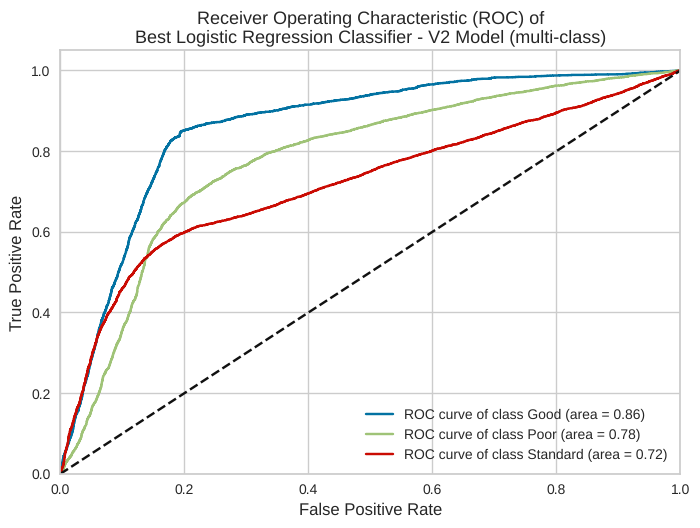

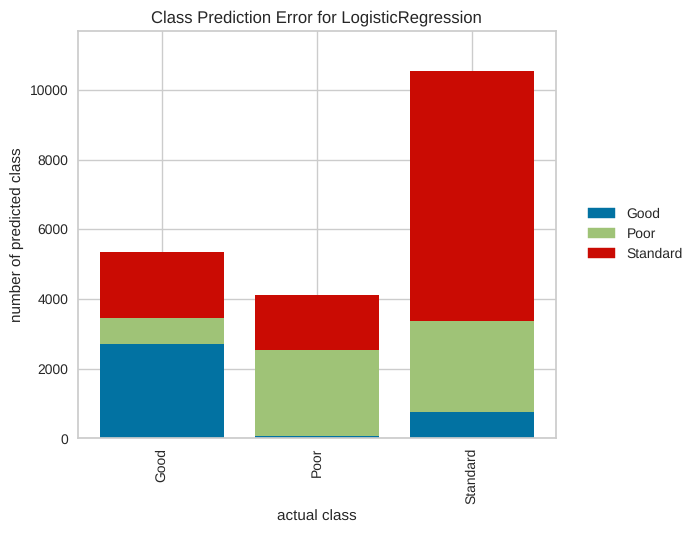

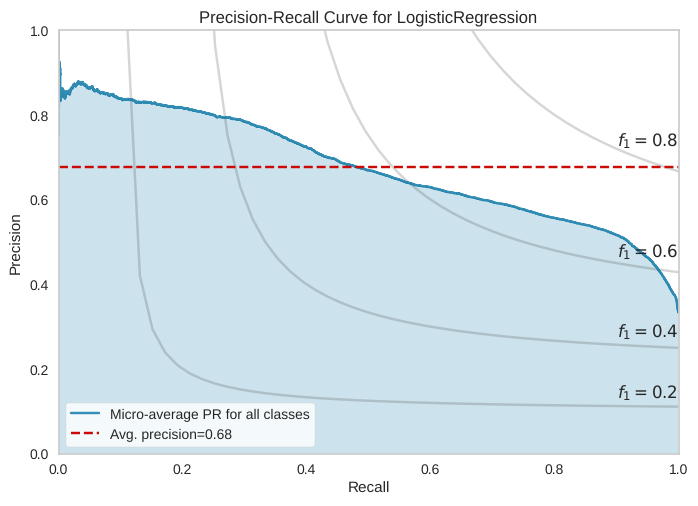

In [39]:
## plot visualisations and classification report:

print(classification_report(y_test_v2, grid_lr_v2.best_estimator_.predict(X_test_v2),
                            target_names=target_names)
      )

auc_scores_lr_v2 = multiclass_roc_auc_score_and_plot(grid_lr_v2.best_estimator_,
                                                      X_test_v2, y_test_v2,
                                                      model_name='Best Logistic Regression Classifier - V2')

class_prediction_error_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator=grid_lr_v2.best_estimator_,
                            is_fitted=True);

precision_recall_curve_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator=grid_lr_v2.best_estimator_,
                            line_per_class=False,
                            is_fitted=False,
                            plot_f1_curves=True, );

Reminding myself the parameters of the grid_gbc_v2's best estimator:

In [40]:
grid_gbc_v2.best_params_

{'estimator__criterion': 'squared_error',
 'estimator__learning_rate': 1,
 'estimator__n_estimators': 150}

**Early Stopping  Gradient Boosting Classifier** for reducing overfit:

              precision    recall  f1-score   support

        Good       0.52      0.80      0.63      3566
        Poor       0.68      0.67      0.67      5799
    Standard       0.79      0.66      0.72     10635

    accuracy                           0.68     20000
   macro avg       0.66      0.71      0.67     20000
weighted avg       0.71      0.68      0.69     20000



Train Accuracy: 0.6946625


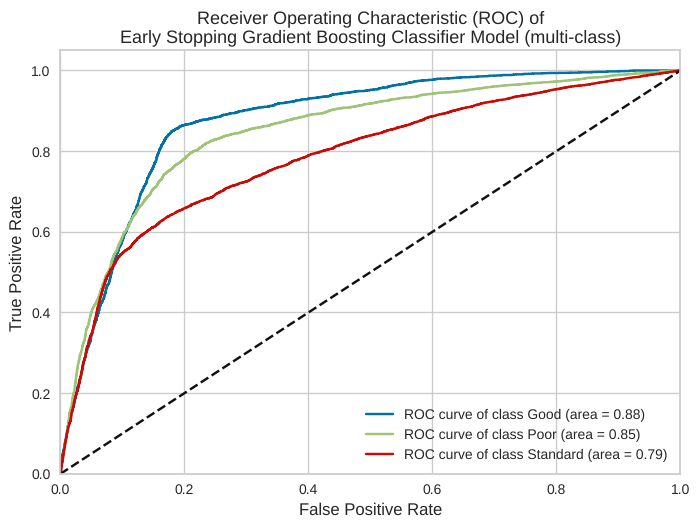

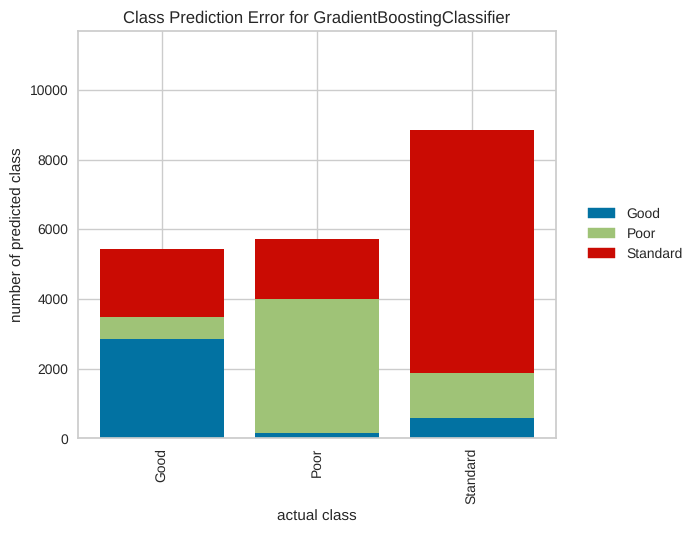

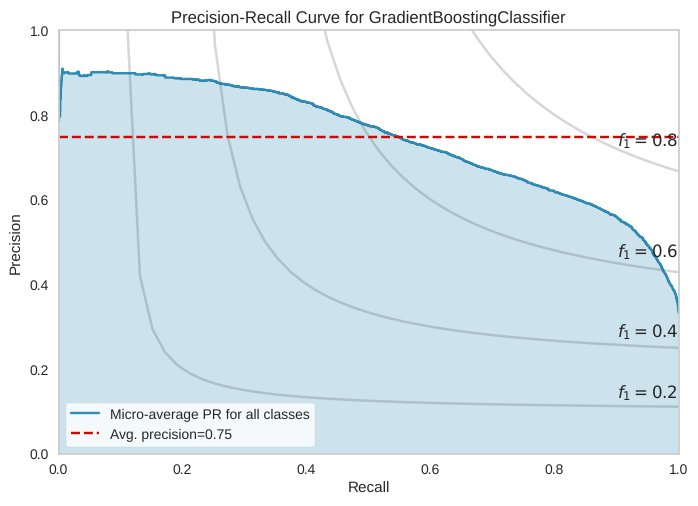

In [41]:
model_gbc_early_stopping = \
    Pipeline([
        ('preprocessor',pr_ord), # it uses tree models, so I do not use One Hot Encoding
        ('estimator', GradientBoostingClassifier(n_estimators= 1000,
                                                 random_state= 42,
                                                 criterion='squared_error',
                                                 learning_rate= 0.01,
                                                 validation_fraction = 0.1, #needed for early stopping
                                                 n_iter_no_change = 10 #needed for early stopping
                                                 ) )
    ])

model_gbc_early_stopping.fit(X_train_v2, y_train_v2)

####################


print(classification_report(y_test_v2, model_gbc_early_stopping.predict(X_test_v2),
                            target_names=target_names)
      )

print('Train Accuracy: '+str(accuracy_score(y_train_v2, model_gbc_early_stopping.predict(X_train_v2)))
      )

auc_scores_gbc_early_stopping = multiclass_roc_auc_score_and_plot(model_gbc_early_stopping,
                                                        X_test_v2, y_test_v2,
                                                        model_name='Early Stopping Gradient Boosting Classifier')

class_prediction_error_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator= model_gbc_early_stopping,
                            is_fitted=True);

precision_recall_curve_plot(X_train_v2, y_train_v2, X_test_v2, y_test_v2,
                            estimator= model_gbc_early_stopping,
                            line_per_class=False,
                            is_fitted=False,
                            plot_f1_curves=True, );

**The gap of the train and test accuracy is reduced. However, I will choose the Gradient Boosting Classifier without early stopping as its performance is better**.

## **Final Results (row-level split)**

In [42]:
grid_models_v3 = \
    [grid_ranf_v2,
     grid_gbc_v2,
     grid_lr_v2,
     grid_ranf_v3
     ]

model_names_v3 = \
    ['Random Forest Classifier - V2',
     'Gradient Boost Classifier - V2',
     'Logistic Regression Classifier - V2',
     'Random Forest Classifier - V3'
     ]

df_metrics_v3 = \
    all_models_metrics(grid_models = grid_models_v3,
                       model_names = model_names_v3,
                       X_train = X_train_v2,
                       X_test = X_test_v2,
                       y_train = y_train_v2,
                       y_test = y_test_v2)

df_metrics_v3


,training_time,train_accuracy,test_accuracy,recall micro-average,precision micro-average,f1_score micro-average
Random Forest Classifier - V2,19.190471,0.948263,0.78395,0.78395,0.78395,0.78395
Gradient Boost Classifier - V2,32.642388,0.778950,0.73955,0.73955,0.73955,0.73955
Logistic Regression Classifier - V2,0.376158,0.614175,0.61685,0.61685,0.61685,0.61685
Random Forest Classifier - V3,47.975013,0.877337,0.80210,0.80210,0.80210,0.80210


Plotting the **Confusion Matrices** of the models demonstrated on the above table (the class names are shown on the axes):

Random Forest Classifier - V2:

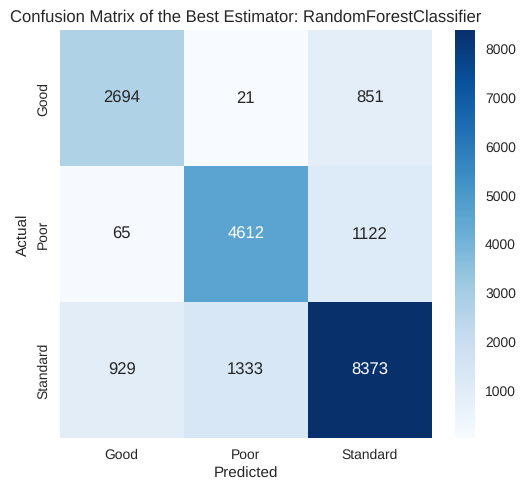

In [43]:
plot_confusion_matrix(grid_search = grid_ranf_v2, X_test=X_test_v2, y_test= y_test_v2)

Gradient Boost Classifier - V2:


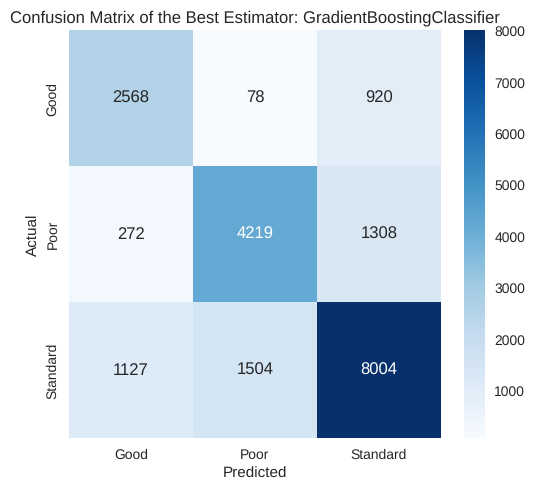

In [44]:
plot_confusion_matrix(grid_search = grid_gbc_v2, X_test=X_test_v2, y_test= y_test_v2)

Random Forest Classifier - V3:

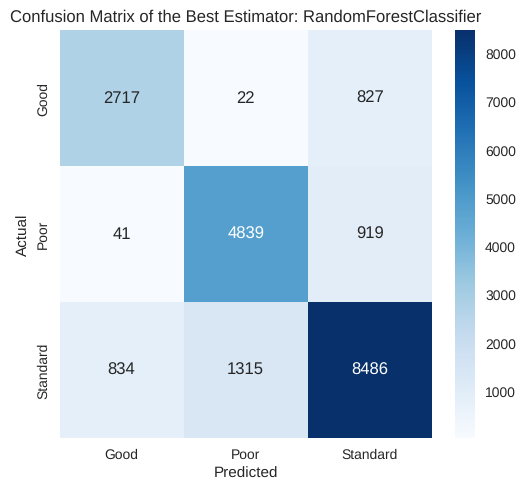

In [45]:
plot_confusion_matrix(grid_search = grid_ranf_v3, X_test=X_test_v2, y_test= y_test_v2)

Logistic Regression Classifier - V2:

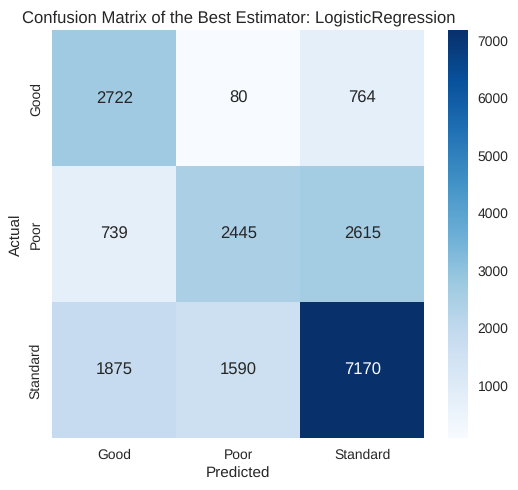

In [46]:
plot_confusion_matrix(grid_search = grid_lr_v2, X_test=X_test_v2, y_test= y_test_v2)

## **Data Leakage Check: Customer-level Validation**

The bigger subset contains **8 monthly records per customer** (12,500 customers x 8 months). The random splitting above (**train_test_split** on rows) places records of the **same customer** in both the training and the test set. As shown below, features like **Annual_Income**, **Outstanding_Debt** and **Credit_Mix** never change for a customer, so a flexible model can recognise (*memorise*) customers that it has already seen, instead of learning patterns that generalise to new customers.

This is a form of **data leakage**: the test scores of the bigger subset are optimistic, because in practice a credit scoring model is used on **new customers**. The checks below confirm the issue:

In [47]:
# share of test observations whose customer also appears in the training set (row-level split):
customers_train_v2 = data_v2.loc[X_train_v2.index, 'Customer_ID']
customers_test_v2 = data_v2.loc[X_test_v2.index, 'Customer_ID']

print('Test observations of customers that also appear in the training set: '
      +str(round(customers_test_v2.isin(customers_train_v2).mean()*100, 2))+'%\n')

# share of customers whose feature (or target) never changes across the 8 months:
for column in ['Annual_Income', 'Outstanding_Debt', 'Credit_Mix', 'Credit_Score']:
    constant_share = (data_v2.groupby('Customer_ID')[column].nunique() == 1).mean()
    print('Customers with a constant '+column+': '+str(round(constant_share*100, 2))+'%')

Test observations of customers that also appear in the training set: 100.0%

Customers with a constant Annual_Income: 100.0%
Customers with a constant Outstanding_Debt: 100.0%
Customers with a constant Credit_Mix: 100.0%
Customers with a constant Credit_Score: 41.66%


To estimate the performance on **new (unseen) customers**, I split the data by **Customer_ID**:
- **GroupShuffleSplit** keeps all the records of a customer either in the training set or in the test set (20% of the customers are kept for testing).
- **GroupKFold** (K=3) is used as the cross validation strategy of **GridSearchCV**, so the hyperparameters are also chosen on unseen customers.

In [48]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

groups_v2 = data_v2['Customer_ID']

# 20% of the customers are kept for testing:
group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(group_splitter.split(X_v2, y_v2, groups=groups_v2))

X_train_grouped, X_test_grouped = X_v2.iloc[train_index], X_v2.iloc[test_index]
y_train_grouped, y_test_grouped = y_v2.iloc[train_index], y_v2.iloc[test_index]
groups_train_grouped = groups_v2.iloc[train_index]

# check:
print('Customers in both the training and the test set: '
      +str(len(set(groups_train_grouped) & set(groups_v2.iloc[test_index]))))
print(f"Baseline accuracy: {y_test_grouped.value_counts(normalize=True).max()*100:.2f}%")

Customers in both the training and the test set: 0
Baseline accuracy: 53.12%


#### Step 1: the same final models on the customer-level split
Below I train the final models of the bigger subset again, **with exactly the same features and hyperparameters**, but on the customer-level split. In other words, the difference from the results above is caused only by the data leakage:

In [49]:
from sklearn.base import clone

# same pipelines and hyperparameters as the best estimators above, trained on the customer-level split:
same_models = \
    {'Logistic Regression Classifier - V2': clone(grid_lr_v2.best_estimator_),
     'Random Forest Classifier - V3': clone(grid_ranf_v3.best_estimator_),
     'Gradient Boost Classifier - V2': clone(grid_gbc_v2.best_estimator_)}

leakage_check = {}

for model_name, model in same_models.items():
    model.fit(X_train_grouped, y_train_grouped)
    leakage_check[model_name] = \
        {'test_accuracy (row-level split)': df_metrics_v3.loc[model_name, 'test_accuracy'],
         'test_accuracy (customer-level split)': accuracy_score(y_test_grouped, model.predict(X_test_grouped))}

df_leakage_check = pd.DataFrame.from_dict(leakage_check, orient='index')
df_leakage_check

,test_accuracy (row-level split),test_accuracy (customer-level split)
Logistic Regression Classifier - V2,0.61685,0.61420
Random Forest Classifier - V3,0.80210,0.66135
Gradient Boost Classifier - V2,0.73955,0.64765


**The scores drop significantly on new customers**, mostly for the tree-based ensembles (Random Forest and Gradient Boosting), which memorise customers. Logistic Regression (a linear model) is almost unaffected.

#### Step 2: tuning the models on unseen customers
Now I fine-tune the models with **GridSearchCV** using the customer-level cross validation (**GroupKFold**). Since the hyperparameters chosen above were optimised on leaked data, I also include simpler (more regularised) values in the parameter grids.

**Important Note**: The preprocessors above (pr_oh, pr_ord) were created from the small subset, so the newly added features (**Num_Bank_Accounts**, **Num_of_Loan**, **Changed_Credit_Limit**) were not actually used by the models of the bigger subset (remainder='drop'). Below I create the preprocessors from the bigger subset, so these features are included:

In [50]:
pr_oh_v2 = \
    Preprocessor_function(data = data_v2[included_features_v2],
                          target_variable = 'Credit_Score',
                          cat_encoder = 'oh',
                          excluded_features = excluded_features
                          ).fit(data_v2[included_features_v2])


pr_ord_v2 = \
    Preprocessor_function(data = data_v2[included_features_v2],
                          target_variable = 'Credit_Score',
                          cat_encoder = 'ord',
                          excluded_features = excluded_features
                          ).fit(data_v2[included_features_v2])

pr_ord_v2

ColumnTransformer(transformers=[('standardscaler', StandardScaler(),
                                 ['Age', 'Annual_Income', 'Outstanding_Debt',
                                  'Total_EMI_per_month', 'Delay_from_due_date',
                                  'Num_of_Delayed_Payment', 'Num_Bank_Accounts',
                                  'Num_of_Loan', 'Changed_Credit_Limit']),
                                ('ordinalencoder', OrdinalEncoder(),
                                 ['Credit_Mix', 'Payment_of_Min_Amount'])])

Training **Logistic Regression** estimators with the customer-level cross validation:

In [51]:
cv_grouped = GroupKFold(n_splits=3)

model_lr_grouped = \
    Pipeline([
        ('preprocessor',pr_oh_v2),
        ('estimator', LogisticRegression(multi_class='multinomial', random_state=42))
    ])

grid_lr_grouped = \
    GridSearchCV(estimator= model_lr_grouped,
                 param_grid= lr_params,
                 scoring= score_metric_used,
                 return_train_score= True,
                 n_jobs = 4,
                 cv = cv_grouped
                 ).fit(X_train_grouped, y_train_grouped, groups= groups_train_grouped)

grid_lr_grouped.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('standardscaler',
                                                  StandardScaler(),
                                                  ['Age', 'Annual_Income',
                                                   'Outstanding_Debt',
                                                   'Total_EMI_per_month',
                                                   'Delay_from_due_date',
                                                   'Num_of_Delayed_Payment',
                                                   'Num_Bank_Accounts',
                                                   'Num_of_Loan',
                                                   'Changed_Credit_Limit']),
                                                 ('onehotencoder',
                                                  OneHotEncoder(drop='if_binary'),
                                                  ['Credit_Mix',
                                                   'Payment_of_Min_Amount'])])),
                ('estimator',
                 LogisticRegression(C=200, max_iter=300,
                                    multi_class='multinomial',
                                    random_state=42))])

              precision    recall  f1-score   support

        Good       0.52      0.72      0.61      3563
        Poor       0.63      0.45      0.53      5813
    Standard       0.69      0.70      0.69     10624

    accuracy                           0.63     20000
   macro avg       0.61      0.63      0.61     20000
weighted avg       0.64      0.63      0.63     20000



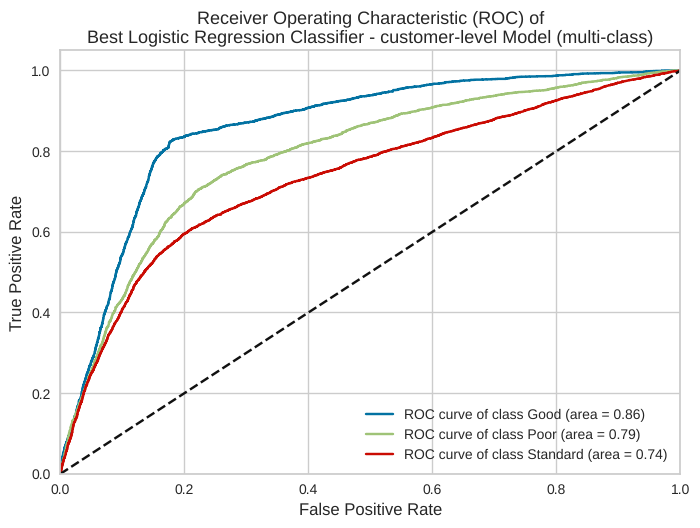

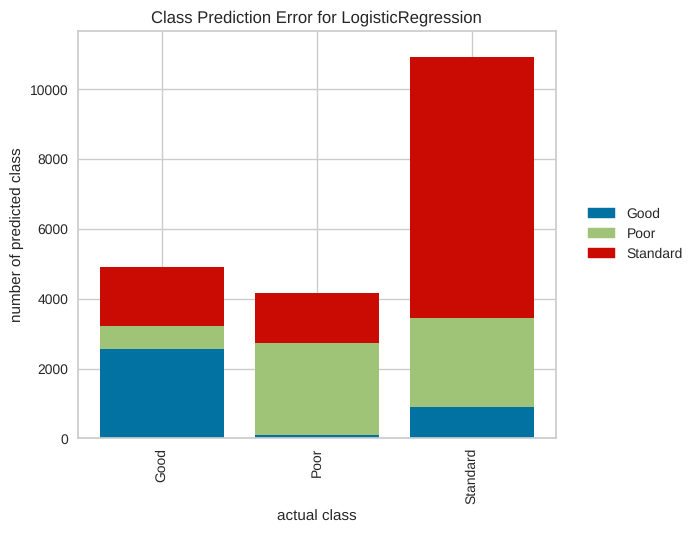

In [52]:
print(classification_report(y_test_grouped, grid_lr_grouped.best_estimator_.predict(X_test_grouped),
                            target_names=target_names)
      )

auc_scores_lr_grouped = multiclass_roc_auc_score_and_plot(grid_lr_grouped.best_estimator_,
                                                           X_test_grouped, y_test_grouped,
                                                           model_name='Best Logistic Regression Classifier - customer-level')

class_prediction_error_plot(X_train_grouped, y_train_grouped, X_test_grouped, y_test_grouped,
                            estimator = grid_lr_grouped.best_estimator_,
                            is_fitted = True);

Training **Random Forest** estimators with the customer-level cross validation:

In [53]:
ranf_params_grouped = {'estimator__n_estimators': [200],
                       'estimator__max_depth': [5, 10, 15],
                       'estimator__min_samples_leaf': [5, 20]
                       }

model_ranf_grouped = \
    Pipeline([
        ('preprocessor',pr_ord_v2), # it uses tree models, so I do not use One Hot Encoding
        ('estimator', RandomForestClassifier(random_state= 42, oob_score = False) )
    ])

grid_ranf_grouped = \
    GridSearchCV(estimator=model_ranf_grouped,
                 param_grid=ranf_params_grouped,
                 scoring=score_metric_used,
                 return_train_score=True,
                 n_jobs=4,
                 cv = cv_grouped
                 ).fit(X_train_grouped, y_train_grouped, groups= groups_train_grouped)

# check best parameters:
grid_ranf_grouped.best_params_

{'estimator__max_depth': 10,
 'estimator__min_samples_leaf': 5,
 'estimator__n_estimators': 200}

              precision    recall  f1-score   support

        Good       0.54      0.77      0.63      3563
        Poor       0.71      0.67      0.69      5813
    Standard       0.78      0.70      0.73     10624

    accuracy                           0.70     20000
   macro avg       0.68      0.71      0.68     20000
weighted avg       0.72      0.70      0.70     20000



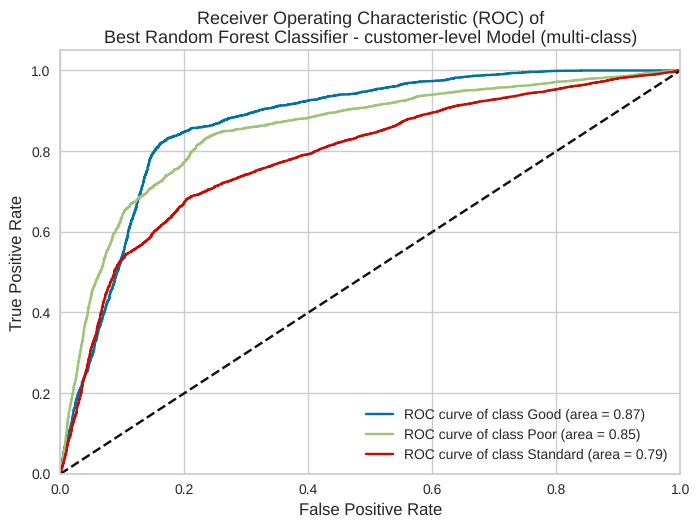

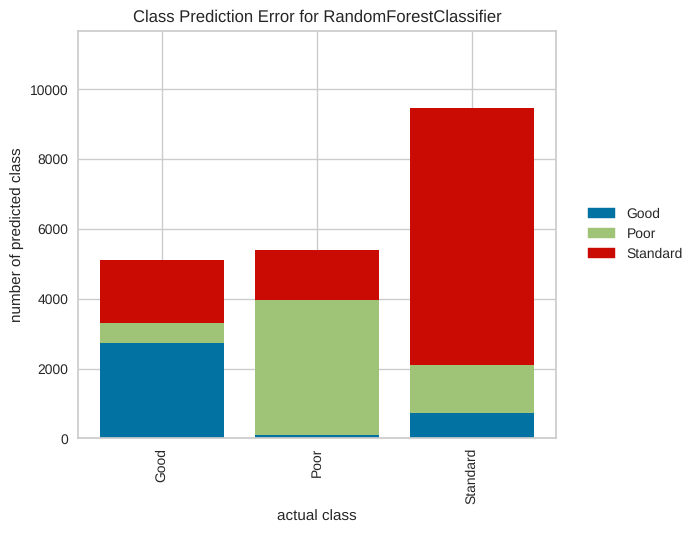

In [54]:
print(classification_report(y_test_grouped, grid_ranf_grouped.best_estimator_.predict(X_test_grouped),
                            target_names=target_names)
      )

auc_scores_ranf_grouped = multiclass_roc_auc_score_and_plot(grid_ranf_grouped.best_estimator_,
                                                             X_test_grouped, y_test_grouped,
                                                             model_name='Best Random Forest Classifier - customer-level')

class_prediction_error_plot(X_train_grouped, y_train_grouped, X_test_grouped, y_test_grouped,
                            estimator = grid_ranf_grouped.best_estimator_,
                            is_fitted = True);

Training **Gradient Boosting** estimators with the customer-level cross validation:

In [55]:
gbc_params_grouped = {'estimator__learning_rate': [0.05, 0.1],
                      'estimator__n_estimators': [50, 100, 200],
                      'estimator__max_depth': [3, 4, 5]
                      }

model_gbc_grouped = \
    Pipeline([
        ('preprocessor',pr_ord_v2), # it uses tree models, so I do not use One Hot Encoding
        ('estimator', GradientBoostingClassifier(random_state= 42) )
    ])

grid_gbc_grouped = \
    GridSearchCV(estimator= model_gbc_grouped,
                 param_grid= gbc_params_grouped,
                 scoring= score_metric_used,
                 return_train_score= True,
                 n_jobs = 4,
                 cv = cv_grouped
                 ).fit(X_train_grouped, y_train_grouped, groups= groups_train_grouped)

grid_gbc_grouped.best_estimator_

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('standardscaler',
                                                  StandardScaler(),
                                                  ['Age', 'Annual_Income',
                                                   'Outstanding_Debt',
                                                   'Total_EMI_per_month',
                                                   'Delay_from_due_date',
                                                   'Num_of_Delayed_Payment',
                                                   'Num_Bank_Accounts',
                                                   'Num_of_Loan',
                                                   'Changed_Credit_Limit']),
                                                 ('ordinalencoder',
                                                  OrdinalEncoder(),
                                                  ['Credit_Mix',
                                                   'Payment_of_Min_Amount'])])),
                ('estimator',
                 GradientBoostingClassifier(learning_rate=0.05, max_depth=5,
                                            n_estimators=50,
                                            random_state=42))])

              precision    recall  f1-score   support

        Good       0.53      0.79      0.63      3563
        Poor       0.72      0.64      0.68      5813
    Standard       0.78      0.69      0.73     10624

    accuracy                           0.69     20000
   macro avg       0.67      0.71      0.68     20000
weighted avg       0.71      0.69      0.70     20000



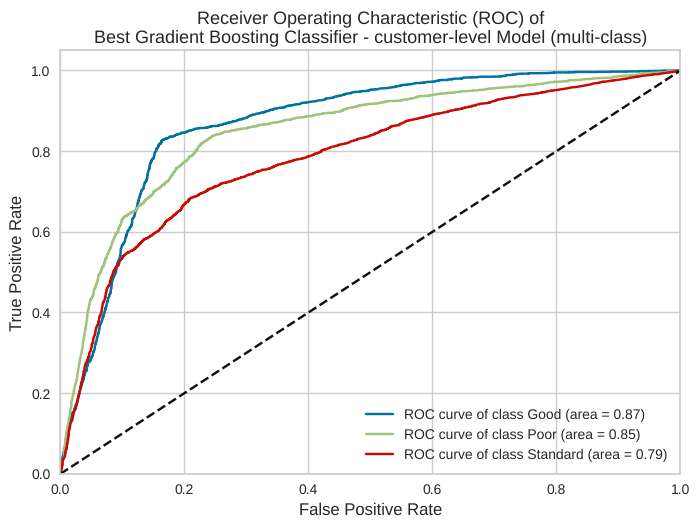

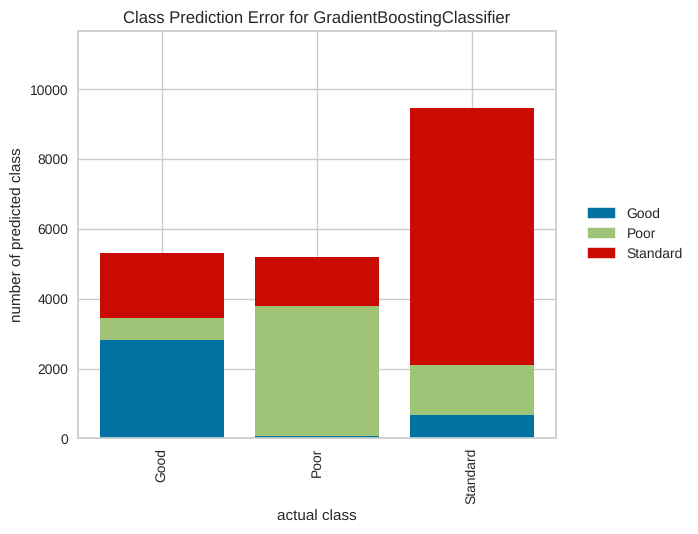

In [56]:
print(classification_report(y_test_grouped, grid_gbc_grouped.best_estimator_.predict(X_test_grouped),
                            target_names=target_names)
      )

auc_scores_gbc_grouped = multiclass_roc_auc_score_and_plot(grid_gbc_grouped.best_estimator_,
                                                            X_test_grouped, y_test_grouped,
                                                            model_name='Best Gradient Boosting Classifier - customer-level')

class_prediction_error_plot(X_train_grouped, y_train_grouped, X_test_grouped, y_test_grouped,
                            estimator = grid_gbc_grouped.best_estimator_,
                            is_fitted = True);

The results of the models that were tuned and evaluated on unseen customers are demonstrated below:

In [57]:
grid_models_grouped = \
    [grid_lr_grouped,
     grid_ranf_grouped,
     grid_gbc_grouped]

model_names_grouped = \
    ['Logistic Regression Classifier - customer-level',
     'Random Forest Classifier - customer-level',
     'Gradient Boost Classifier - customer-level']


df_metrics_grouped = \
    all_models_metrics(grid_models = grid_models_grouped,
                       model_names = model_names_grouped,
                       X_train = X_train_grouped,
                       X_test = X_test_grouped,
                       y_train = y_train_grouped,
                       y_test = y_test_grouped)

df_metrics_grouped

,training_time,train_accuracy,test_accuracy,recall micro-average,precision micro-average,f1_score micro-average
Logistic Regression Classifier - customer-level,0.403081,0.632888,0.6345,0.6345,0.6345,0.6345
Random Forest Classifier - customer-level,9.323076,0.720000,0.6993,0.6993,0.6993,0.6993
Gradient Boost Classifier - customer-level,18.416854,0.700712,0.6948,0.6948,0.6948,0.6948


Comparing the test accuracy of the final models before and after fixing the data leakage:

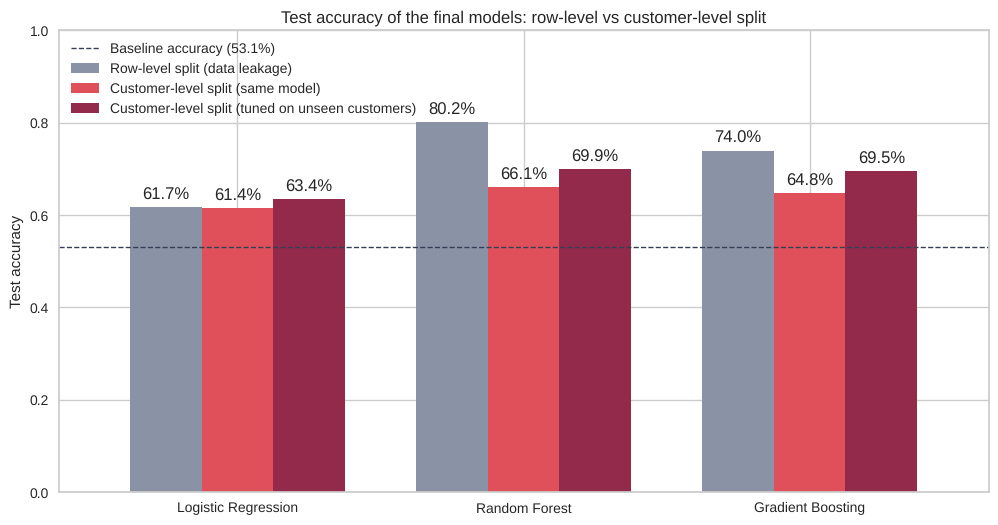

,Row-level split (data leakage),Customer-level split (same model),Customer-level split (tuned on unseen customers)
Logistic Regression,0.61685,0.61420,0.6345
Random Forest,0.80210,0.66135,0.6993
Gradient Boosting,0.73955,0.64765,0.6948


In [58]:
df_leakage_comparison = \
    pd.DataFrame({'Row-level split (data leakage)': df_leakage_check['test_accuracy (row-level split)'].values,
                  'Customer-level split (same model)': df_leakage_check['test_accuracy (customer-level split)'].values,
                  'Customer-level split (tuned on unseen customers)': df_metrics_grouped['test_accuracy'].values},
                 index=['Logistic Regression', 'Random Forest', 'Gradient Boosting'])

ax = df_leakage_comparison.plot(kind='bar', figsize=(12, 6), rot=0, width=0.75,
                                color=['#8A93A6', '#E0505A', '#932A4B'])

# accuracy on top of every bar:
for container in ax.containers:
    ax.bar_label(container, labels=[str(round(value*100, 1))+'%' for value in container.datavalues], padding=3)

# baseline accuracy of the customer-level test set:
baseline_grouped = y_test_grouped.value_counts(normalize=True).max()
ax.axhline(baseline_grouped, color='#343F56', linestyle='--', linewidth=1,
           label='Baseline accuracy ('+str(round(baseline_grouped*100, 1))+'%)')

plt.title('Test accuracy of the final models: row-level vs customer-level split')
plt.ylabel('Test accuracy')
plt.ylim(0, 1)
plt.legend(loc='upper left')
plt.show()

df_leakage_comparison

Which features drive the predictions of the final tree-based models?

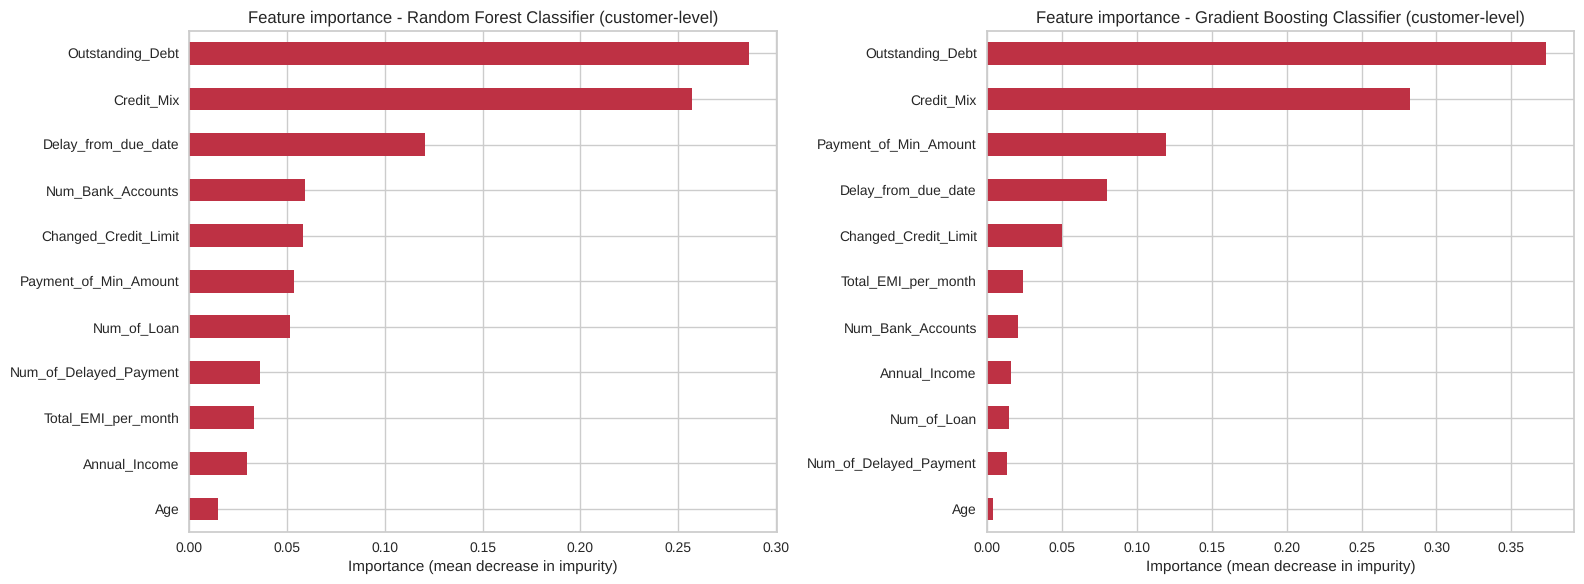

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (model_name, grid_model) in zip(axes, [('Random Forest Classifier', grid_ranf_grouped),
                                               ('Gradient Boosting Classifier', grid_gbc_grouped)]):
    best_model = grid_model.best_estimator_
    feature_importance = \
        pd.Series(best_model.named_steps['estimator'].feature_importances_,
                  index=[name.split('__')[1] for name in best_model.named_steps['preprocessor'].get_feature_names_out()]
                  ).sort_values()

    feature_importance.plot(kind='barh', ax=ax, color='#BE3144')
    ax.set_title('Feature importance - '+model_name+' (customer-level)')
    ax.set_xlabel('Importance (mean decrease in impurity)')

plt.tight_layout()
plt.show()

Plotting the **Confusion Matrices** of the final customer-level models:

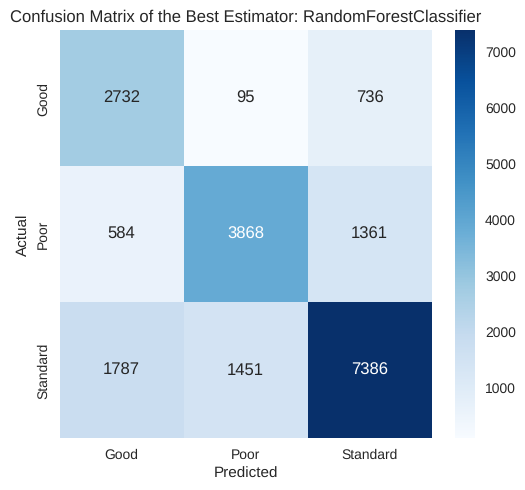

In [60]:
plot_confusion_matrix(grid_search = grid_ranf_grouped, X_test=X_test_grouped, y_test= y_test_grouped)

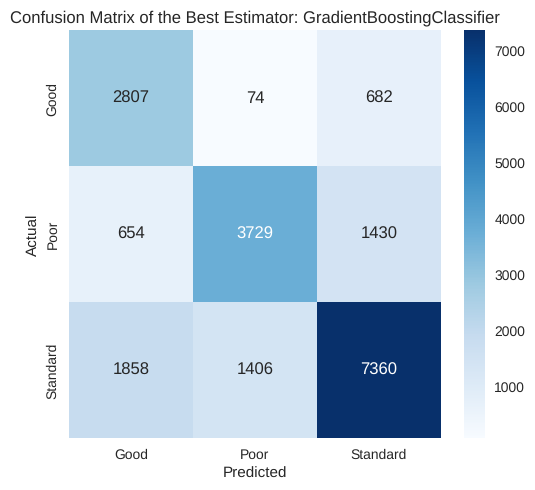

In [61]:
plot_confusion_matrix(grid_search = grid_gbc_grouped, X_test=X_test_grouped, y_test= y_test_grouped)

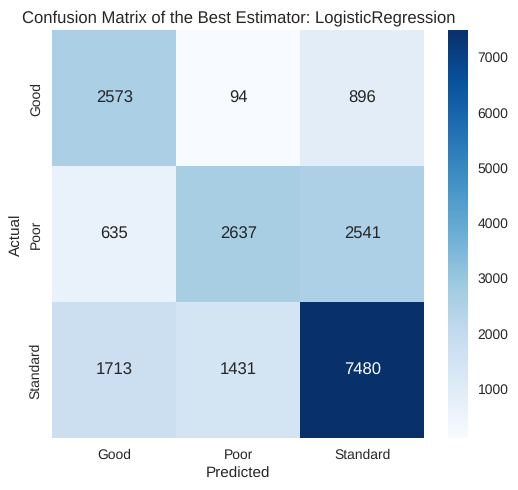

In [62]:
plot_confusion_matrix(grid_search = grid_lr_grouped, X_test=X_test_grouped, y_test= y_test_grouped)

**Customer-level validation results**:
- On **unseen customers** the tree-based ensembles score much lower with exactly the same models (Random Forest: 80.2% → 66.1%, Gradient Boosting: 74.0% → 64.8%), while Logistic Regression is almost unaffected (61.7% → 61.4%). This confirms the data leakage of the row-level split.
- Tuning on unseen customers selects **simpler (more regularised) models**: a Random Forest with max_depth=10 and min_samples_leaf=5, and a Gradient Boosting Classifier with learning_rate=0.05 and only 50 estimators. The gap between their train and test accuracy is small (2.1 and 0.6 points), so they no longer memorise customers.
- The tuned models also use the three features that were added for the bigger subset, and they recover a large part of the gap: about 70% test accuracy on unseen customers, against a baseline of 53.1%.

#### Concluding - Results

According to the above results of the final models (customer-level validation):
- The row-level split of the bigger subset gave optimistic results because of data leakage (records of the same customers were in both the training and the test set). The final models are evaluated on **unseen customers**, like a credit scoring model in production.
- The **Random Forest Classifier** gives the best results on unseen customers: 69.9% accuracy (baseline 53.1%) and AUC scores of 0.87 (Good), 0.85 (Poor) and 0.79 (Standard). Tuned with the customer-level cross validation it is regularised (max_depth=10, min_samples_leaf=5), so the overfitting of the earlier Random Forests, which memorised customers, is solved. We could use this model if performance is our goal.
- The **Gradient Boosting Classifier** is a close alternative (69.5% accuracy) with an even smaller gap between the train and test accuracy.
- If training speed is our goal we should choose **Logistic Regression** (63.4% accuracy). Logistic Regression is widely used on Credit Scoring systems and has a good performance (not excellent). For enterprise use, Logistic Regression is an excellent model as it is quite fast on fitting phase and easy to interpret.

Below, the ROC curves of the final chosen models are demonstrated along with their confusion matrices:

Final Random Forest Classifier:
![roc_rf](./images/ROC_rf_final.png)
![cm_rf](./images/cm_rf_final.png)

Final Logistic Regression Classifier:
![roc_lr](./images/ROC_lr_final.png)
![cm_lr](./images/cm_lr_final.png)

**Important reminder**: Because we use the micro-average, the accuracy, precision, recall and f1 score are the same.

In [63]:
# table of final results (customer-level):
df_metrics_grouped

,training_time,train_accuracy,test_accuracy,recall micro-average,precision micro-average,f1_score micro-average
Logistic Regression Classifier - customer-level,0.403081,0.632888,0.6345,0.6345,0.6345,0.6345
Random Forest Classifier - customer-level,9.323076,0.720000,0.6993,0.6993,0.6993,0.6993
Gradient Boost Classifier - customer-level,18.416854,0.700712,0.6948,0.6948,0.6948,0.6948


Lastly, the structure of the final chosen models is presented below.

**Final Random Forest Classifier**:
![pipeline_rf](./images/pipeline_rf_final.png)

**Final Logistic Regression Classifier**:
![pipeline_lr](./images/pipeline_lr_final.png)



#### Conclusion: 
As indicated from the results above, machine learning could be used to produce credit scores of a financial institution's customers.
More specifically, two models could be used in our case; the Random Forest Classifier or the Logistic Regression.
Furthermore, the validation strategy must reflect how the models are used: splitting the data by customer revealed that the first results of the bigger subset were inflated by data leakage, and it produced simpler models that generalise better to new customers.

#### Next Steps and Recommendations
Below there are some recommendations and next steps to incorporate into the project:

- We could use the Optuna library for more advanced and optimised hyperparameters tuning. Optuna uses state-of-the-art algorithms to find optimal solutions (reduce errors-maximise scores). One example is the Nondominated Sorting Genetic Algorithm II (NSGAII).
- We could develop Neural Network models using Tensorflow and Keras. For example CNNs for classification on tabular data could provide excellent performance.
- We could use expert AI models like ANFIS (Artificial Neuro-fuzzy Inference System) which is a more interpretable NN architecture that uses fuzzy logic to explain the rules that it creates. ANFIS could be an excellent case especially if interpretability is needed along with accurate predictions.
- Generally, we could integrate approaches like the SHAP values to better explain the models created.
- We could validate the models with a **time-based split** (train on the earlier months and test on the later months), which simulates how a credit scoring model is used in production.
- Before using the models for lending decisions, we should perform a **fairness (bias) analysis**, e.g. compare the errors across age groups and occupations. This is essential for the financial inclusion objective of the project.

In [64]:
print('Notebook runs without errors - End of Notebook 4')

Notebook runs without errors - End of Notebook 4
